# Joint PLDS batch fit on real data

Fits the Poisson LDS and the stim matrix B jointly on control and stim reaches (target A),
then shows the smoothed latents.

1. `fit_initial` on control trials (no stim, so B drops out).
2. `fit_batch` (EM) on control + stim trials together. E-step: joint EKF over
   [x; vec(B)]. M-step: refit A, C, d, Q, b with B at its posterior mean.
3. `batch_smooth_latents` with the fitted B for the smoothed latents.

Each array in `ARRAYS` (NPRW, the stimulated array, and the Utah array UA) gets its own
model, latents and plots; `runs[ARRAY]` holds an array's data and results.

`BLANK` sets which arrays drop the stim window. NPRW must (its stim window is missing at the
source); UA is kept through stimulation by default, with the stim input still marking those
bins, so its alignment and fan windows extend to stim onset. A section near the end compares
UA fit with and without its stim-window bins.

All of `STIM_BLOCKS` is fit, smoothed, rotated and aligned together; `SHOW_BLOCKS` only picks
which stim blocks the plots and the GIF draw against control.

In [23]:
import os
os.environ.setdefault("XLA_PYTHON_CLIENT_PREALLOCATE", "false")

import json
import re
from pathlib import Path
from types import SimpleNamespace

import jax.numpy as jnp
import jax.random as jr
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm, ListedColormap
import numpy as np
from simulations import make_toeplitz_V

from wasabi import BPosterior, TrialBuffer, batch_smooth_latents, fit_batch, fit_initial, make_poisson_lds
from wasabi.utils import softplus

# Load data

In [24]:
PERI_ROOT = Path("/home/bryan/mnt/cullen_data/Current Project Databases - NHP/2025 Cerebellum prosthesis/Nike/20251203_NRR_RW011/results/checkpoints/PeriStim")
TARGET = "target_A"
# Each array is fit on its own: NPRW is the stimulated array, UA the Utah array
ARRAYS = ("NPRW", "UA")
# Stim blocks (BR numbers): all of STIM_BLOCKS are fit together with control; SHOW_BLOCKS only
# chooses which of them are drawn (a single block plots one trace against control).
# 12-21 stim 8 contiguous channels each
STIM_BLOCKS = list(range(12, 22))
SHOW_BLOCKS = [12, 14, 17, 20, 21] #[17] #[20]
assert set(SHOW_BLOCKS) <= set(STIM_BLOCKS), "can only display blocks that were fit"
# Output file tag: the displayed blocks, plus the fitted ones when they differ
FIG_TAG = "BR" + "-".join(map(str, SHOW_BLOCKS))
if SHOW_BLOCKS != STIM_BLOCKS:
    FIG_TAG += "_fit" + "-".join(map(str, STIM_BLOCKS))
STIM_DUR_MS = 100.0

control_files = sorted((PERI_ROOT / "control_reaches" / TARGET).glob("peristim__*.npz"))
stim_files = sorted(
    f for br in STIM_BLOCKS for f in (PERI_ROOT / "stim_reaches" / TARGET).glob(f"*BR_{br:03d}_*.npz")
)
print(f"{len(control_files)} control files, {len(stim_files)} stim files")

3 control files, 10 stim files


In [25]:
# Shared time axis and stim inputs, from NPRW (the stim channels are NPRW channels)
t_ms = np.load(control_files[0])["NPRW_rel_t"]
n_ch = np.load(control_files[0])["NPRW_counts"].shape[1]

# The NPRW stim peristim extraction drops the blanked window instead of masking it, leaving a
# gap in the time axis. Reinsert it as NaN bins so stim trials share the control time axis.
stim_t_raw = np.load(stim_files[0])["NPRW_rel_t"]
gap = int(np.argmax(np.diff(stim_t_raw)))
n_insert = len(t_ms) - len(stim_t_raw)
assert np.allclose(np.concatenate([stim_t_raw[: gap + 1], stim_t_raw[gap + 1 :]]),
                   np.delete(t_ms, np.arange(gap + 1, gap + 1 + n_insert)), atol=1.5)
stim_bins = np.flatnonzero((t_ms >= 0) & (t_ms < STIM_DUR_MS))
blank_ms = (t_ms[gap], t_ms[gap + n_insert + 1])
blanked_bins = np.arange(gap + 1, gap + 1 + n_insert)

# Which arrays drop the stim window. NPRW has to: its stim window is missing at the source. UA is
# recorded through stimulation, so it can be kept; the stim input still marks those bins, so the
# model sees the perturbation either way (any stim artifact on UA is then absorbed by B).
BLANK = {"NPRW": True, "UA": False}
assert BLANK["NPRW"], "NPRW has no counts in the stim window"


def array_counts(f, array, stim, kind="counts"):
    """(trials, ch, T) counts of `array` on the NPRW control time axis, NaN over the blanked bins
    for stim trials. kind="rates_hz" gives the saved smoothed firing rates on the same bins."""
    npz = np.load(f)
    counts = npz[f"{array}_{kind}"].astype(float)
    if array == "UA":
        # UA counts are 20 ms windows every 5 ms, so neighbouring bins overlap. Keep the windows
        # centred on the NPRW bins, which tile time without overlap. The extraction does not blank
        # UA; with BLANK["UA"] the NPRW bins are blanked too, so both arrays see stim the same way.
        t_ua = npz["UA_rel_t"]
        idx = np.abs(t_ua[:, None] - t_ms).argmin(axis=0)
        assert np.allclose(t_ua[idx], t_ms), "UA bins do not line up with the NPRW bins"
        counts = counts[:, :, idx]
        if stim and BLANK["UA"]:
            counts[:, :, blanked_bins] = np.nan
    elif stim:
        blank = np.full((counts.shape[0], counts.shape[1], n_insert), np.nan)
        counts = np.concatenate([counts[:, :, : gap + 1], blank, counts[:, :, gap + 1 :]], axis=2)
    return counts


stim_inputs, patterns, pattern_id = [], [], []
for j, f in enumerate(stim_files):
    npz = np.load(f, allow_pickle=True)
    n_trials = npz["NPRW_counts"].shape[0]
    channels = np.asarray(json.loads(npz["nprw_meta_json"].item())["stim_channels"], dtype=int) - 1

    pattern = np.zeros(n_ch)
    pattern[channels] = 1.0
    s = np.zeros((n_trials, len(t_ms), n_ch))
    s[:, stim_bins] = pattern
    stim_inputs.append(s)
    patterns.append(pattern)
    pattern_id += [j] * n_trials

patterns = np.stack(patterns)
pattern_id = np.asarray(pattern_id)
pattern_block = [int(re.search(r"BR_(\d+)", f.name).group(1)) for f in stim_files]  # BR number per pattern
S_stim = jnp.asarray(np.concatenate(stim_inputs))

# Per array: (trials, T, N) counts for the model; keep is False where any channel is blanked
runs = {}
for ARRAY in ARRAYS:
    control_counts = np.concatenate([array_counts(f, ARRAY, stim=False) for f in control_files])
    stim_counts = np.concatenate([array_counts(f, ARRAY, stim=True) for f in stim_files])
    # The model uses one channel count for both the observations and the stim input
    assert control_counts.shape[1] == n_ch, f"{ARRAY} has {control_counts.shape[1]} channels, stim input {n_ch}"
    Y_control = jnp.asarray(control_counts.transpose(0, 2, 1))
    Y_stim = jnp.asarray(stim_counts.transpose(0, 2, 1))
    runs[ARRAY] = SimpleNamespace(
        Y_control=Y_control, Y_stim=Y_stim,
        keep_control=jnp.all(jnp.isfinite(Y_control), axis=2), keep_stim=jnp.all(jnp.isfinite(Y_stim), axis=2),
        blanked=BLANK[ARRAY],
    )
    print(f"{ARRAY}: control {Y_control.shape}, stim {Y_stim.shape}, "
          f"blanked bins {np.flatnonzero(~np.asarray(runs[ARRAY].keep_stim[0])).tolist()}")
S_control = jnp.zeros_like(runs[ARRAYS[0]].Y_control)

print(f"{len(patterns)} patterns, stim channels per pattern:",
      {b: np.flatnonzero(p)[[0, -1]].tolist() for b, p in zip(pattern_block, patterns)})
print(f"stim bins {stim_bins}")


def shade_blank(ax, r):
    """Grey band over the stim window, for arrays whose counts there were dropped."""
    if r.blanked:
        ax.axvspan(*blank_ms, color="0.85", zorder=0)

NPRW: control (19, 70, 128), stim (62, 70, 128), blanked bins [39, 40, 41, 42, 43, 44, 45]
UA: control (19, 70, 128), stim (62, 70, 128), blanked bins []
10 patterns, stim channels per pattern: {12: [0, 7], 13: [4, 11], 14: [8, 15], 15: [12, 19], 16: [16, 23], 17: [20, 27], 18: [24, 31], 19: [28, 35], 20: [32, 39], 21: [36, 43]}
stim bins [40 41 42 43 44]


# Fit

In [26]:
STATE_DIM = 4
BETA_STIM = 1.0
BETA_EMIT = 1.0
SPREAD_WIDTH = 3.0  # Toeplitz stim spread V across neighbouring channels

def fit_control(name, r):
    """1. Control trials only: B drops out, so this fits A, C, d, Q."""
    model = make_poisson_lds(
        STATE_DIM, jnp.asarray(make_toeplitz_V(n_ch, SPREAD_WIDTH)), jr.key(0),
        mean_rate=jnp.nanmean(r.Y_control, axis=(0, 1)), beta_stim=BETA_STIM, beta_emit=BETA_EMIT,
    )
    control_buffer = TrialBuffer.empty(len(r.Y_control), len(t_ms), n_ch).extend(r.Y_control, S_control, r.keep_control)
    r.model, r.init_losses = fit_initial(model, control_buffer, num_steps=500)
    print(f"{name}: control fit NLL per bin: {r.init_losses[0]:.4f} -> {r.init_losses[-1]:.4f}")


for ARRAY, r in runs.items():
    fit_control(ARRAY, r)

NPRW: control fit NLL per bin: 62.2448 -> 56.3761
UA: control fit NLL per bin: 116.5053 -> 106.9176


In [27]:
# 2. Joint batch EM on control + stim trials. Control trials have zero stim input, so they
# only constrain the dynamics; stim trials constrain both the dynamics and B.
S_all = jnp.concatenate([S_control, S_stim])
is_stim = np.r_[np.zeros(len(S_control), bool), np.ones(len(S_stim), bool)]

def fit_joint(name, r):
    """2. Joint batch EM on control + stim trials, from the control fit."""
    r.Y_all = jnp.concatenate([r.Y_control, r.Y_stim])
    r.keep_all = jnp.concatenate([r.keep_control, r.keep_stim])
    buffer = TrialBuffer.empty(len(r.Y_all), len(t_ms), n_ch).extend(r.Y_all, S_all, r.keep_all)
    r.model, r.B_post, r.em_losses = fit_batch(
        r.model, BPosterior.from_prior(STATE_DIM, n_ch, prior_var=1.0), buffer,
        num_iters=10, refit_steps=50,
    )
    r.B_fit = r.B_post.B
    print(f"{name}: NLL per bin at the end of each EM iteration:", np.round(np.asarray(r.em_losses[:, -1]), 4))
    print(f"{name}: |B| = {float(jnp.linalg.norm(r.B_fit)):.3f}, b = {float(r.model.dynamics.b):.3f}")
    print(f"{name}: singular values of A:", np.round(np.asarray(jnp.linalg.svd(r.model.dynamics.A, compute_uv=False)), 4))


for ARRAY, r in runs.items():
    fit_joint(ARRAY, r)

NPRW: NLL per bin at the end of each EM iteration: [63.0637 62.7394 62.5664 62.4785 62.4516 62.4245 62.4233 62.4251 62.4571
 62.5093]
NPRW: |B| = 2.410, b = -0.472
NPRW: singular values of A: [0.999  0.999  0.9656 0.9337]
UA: NLL per bin at the end of each EM iteration: [110.2591 110.1335 109.9658 109.8649 109.823  109.8027 109.8022 109.8153
 109.8209 109.8264]
UA: |B| = 6.057, b = 1.811
UA: singular values of A: [0.999  0.999  0.6236 0.2927]


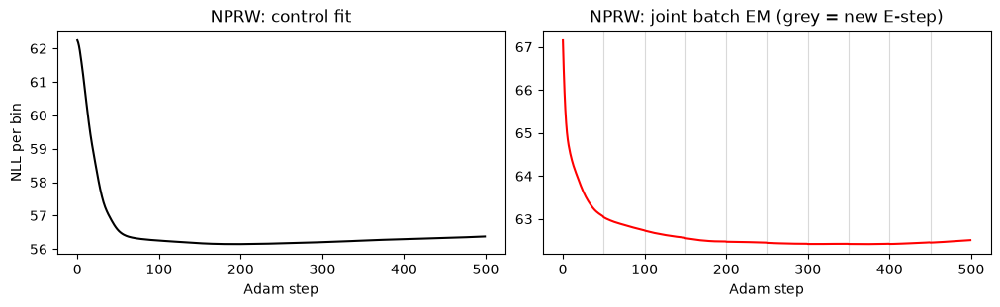

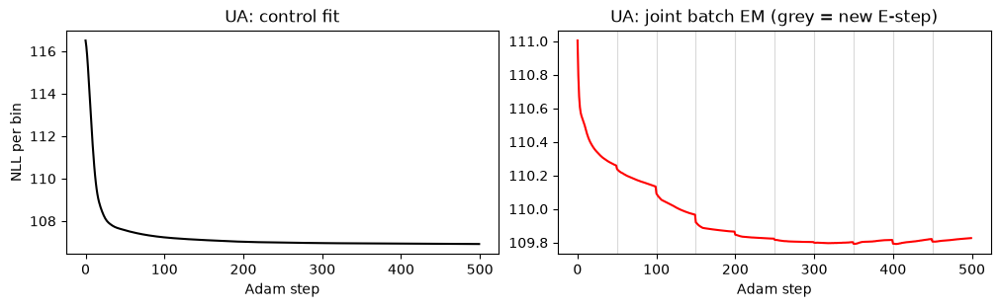

In [28]:
for ARRAY, r in runs.items():
    fig, axes = plt.subplots(1, 2, figsize=(10, 3), constrained_layout=True)
    axes[0].plot(r.init_losses, color="k")
    axes[0].set_title(f"{ARRAY}: control fit"); axes[0].set_xlabel("Adam step"); axes[0].set_ylabel("NLL per bin")
    axes[1].plot(np.asarray(r.em_losses).ravel(), color="r")
    for i in range(1, len(r.em_losses)):
        axes[1].axvline(i * r.em_losses.shape[1], color="0.85", lw=0.8, zorder=0)
    axes[1].set_title(f"{ARRAY}: joint batch EM (grey = new E-step)"); axes[1].set_xlabel("Adam step")
    plt.show()

# Smoothed latents

The latent basis is only defined up to rotation, so the smoothed means are rotated onto
their principal axes (an orthogonal rotation, so C x is unchanged): z₁ has the most variance.

In [29]:
def smooth_and_rotate(name, r):
    """3. RTS smoother with B fixed at the fitted posterior mean, rotated onto principal axes."""
    r.posts = batch_smooth_latents(r.model, r.B_fit, r.Y_all, S_all, r.keep_all)
    x_smooth = np.asarray(r.posts.smoothed_means)        # (trials, T, K)
    x_cov = np.asarray(r.posts.smoothed_covs)            # (trials, T, K, K)

    flat = x_smooth.reshape(-1, STATE_DIM)
    _, _, Wt = np.linalg.svd(flat - flat.mean(axis=0), full_matrices=False)
    r.R = Wt.T                                           # columns are the principal axes
    r.z = x_smooth @ r.R
    r.z_sd = np.sqrt(np.einsum("ki,ntkl,li->nti", r.R, x_cov, r.R))   # per-axis smoothed std
    r.z_control, r.z_stim = r.z[~is_stim], r.z[is_stim]
    print(f"{name}: fraction of latent variance per axis:",
          np.round(np.var(r.z, axis=(0, 1)) / np.var(r.z, axis=(0, 1)).sum(), 3))


for ARRAY, r in runs.items():
    smooth_and_rotate(ARRAY, r)

# Plots start here; the trimmed bins are still used by the fit and the smoother
PLOT_FROM_MS = -400.0
tp = t_ms >= PLOT_FROM_MS

# Plots draw only the SHOW_BLOCKS patterns. Each pattern keeps its colour from the full set of
# fitted patterns, so a block looks the same whichever blocks are shown.
show_ids = [pattern_block.index(b) for b in SHOW_BLOCKS]  # pattern index per displayed block
pattern_colors = plt.cm.viridis(np.linspace(0, 0.95, len(patterns)))
colors = pattern_colors[show_ids]
sm = plt.cm.ScalarMappable(cmap=ListedColormap(colors), norm=BoundaryNorm(np.arange(len(colors) + 1) - 0.5, len(colors)))


def block_colorbar(fig, ax, **kwargs):
    """Discrete colour bar labelled by BR block, matching `colors`."""
    cbar = fig.colorbar(sm, ax=ax, ticks=range(len(colors)), label="stim block", **kwargs)
    cbar.set_ticklabels([f"BR {b}" for b in SHOW_BLOCKS])
    return cbar

NPRW: fraction of latent variance per axis: [0.434 0.282 0.189 0.095]
UA: fraction of latent variance per axis: [0.686 0.159 0.109 0.046]


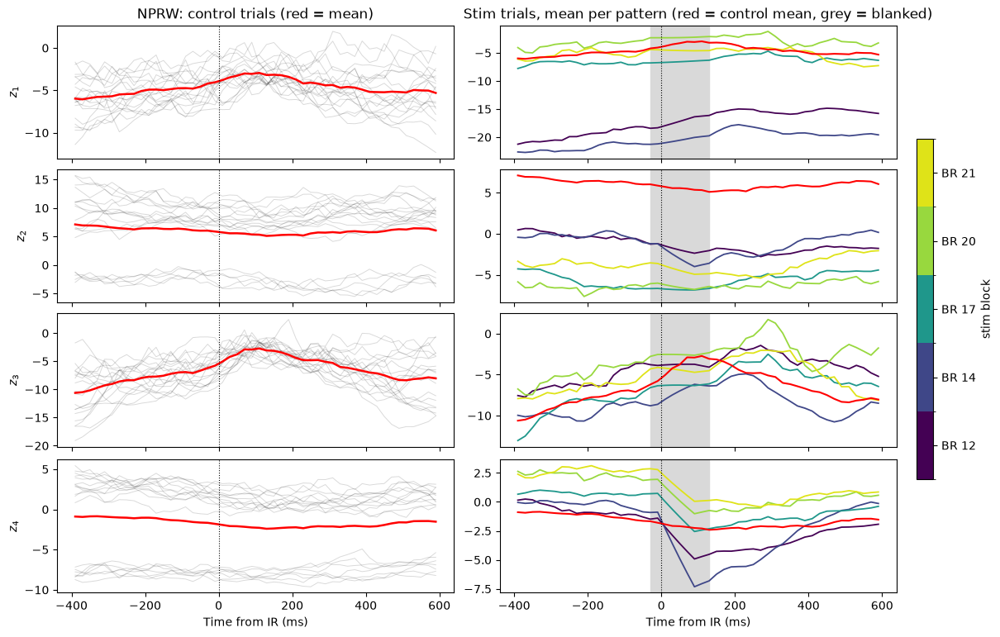

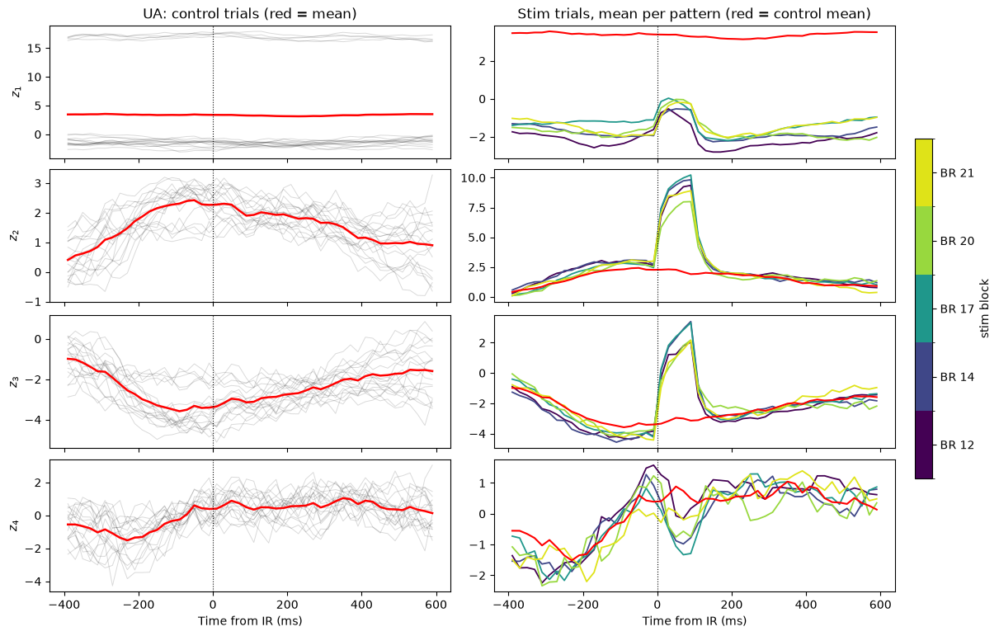

In [30]:
for ARRAY, r in runs.items():
    fig, axes = plt.subplots(STATE_DIM, 2, figsize=(12, 1.9 * STATE_DIM), constrained_layout=True, sharex=True)
    for k in range(STATE_DIM):
        # Left: control trials and their mean
        ax = axes[k, 0]
        ax.plot(t_ms[tp], r.z_control[:, tp, k].T, color="k", alpha=0.15, lw=0.7)
        ax.plot(t_ms[tp], r.z_control[:, tp, k].mean(axis=0), color="r", lw=1.8)
        ax.set_ylabel(f"$z_{k + 1}$")

        # Right: mean per stim pattern, control mean for reference
        ax = axes[k, 1]
        for j, color in zip(show_ids, colors):
            ax.plot(t_ms[tp], r.z_stim[pattern_id == j][:, tp, k].mean(axis=0), color=color, lw=1.3)
        ax.plot(t_ms[tp], r.z_control[:, tp, k].mean(axis=0), color="r", lw=1.5)
        shade_blank(ax, r)

    for ax in axes.ravel():
        ax.axvline(0, color="k", ls=":", lw=0.8)
    axes[0, 0].set_title(f"{ARRAY}: control trials (red = mean)")
    axes[0, 1].set_title("Stim trials, mean per pattern (red = control mean" + (", grey = blanked)" if r.blanked else ")"))
    axes[-1, 0].set_xlabel("Time from IR (ms)"); axes[-1, 1].set_xlabel("Time from IR (ms)")
    block_colorbar(fig, axes[:, 1], shrink=0.6)
    plt.show()

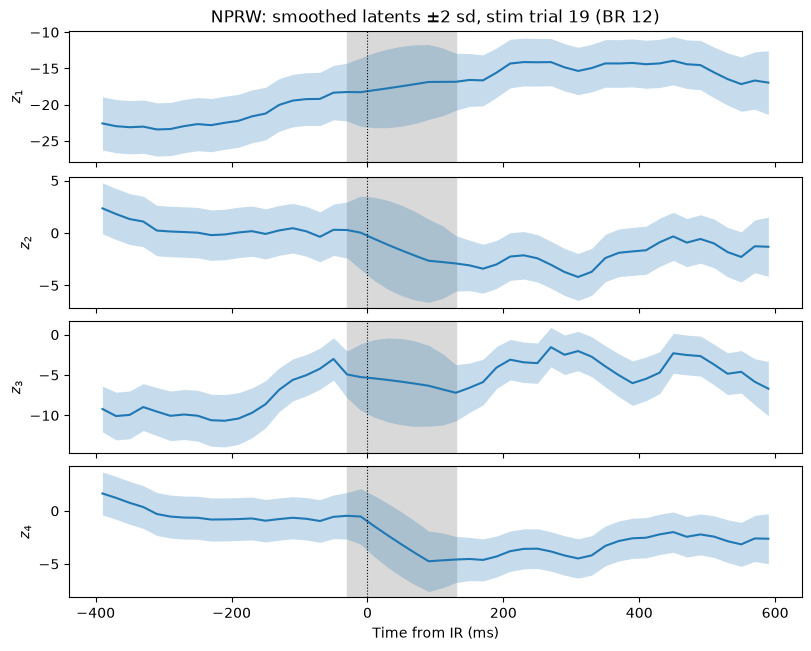

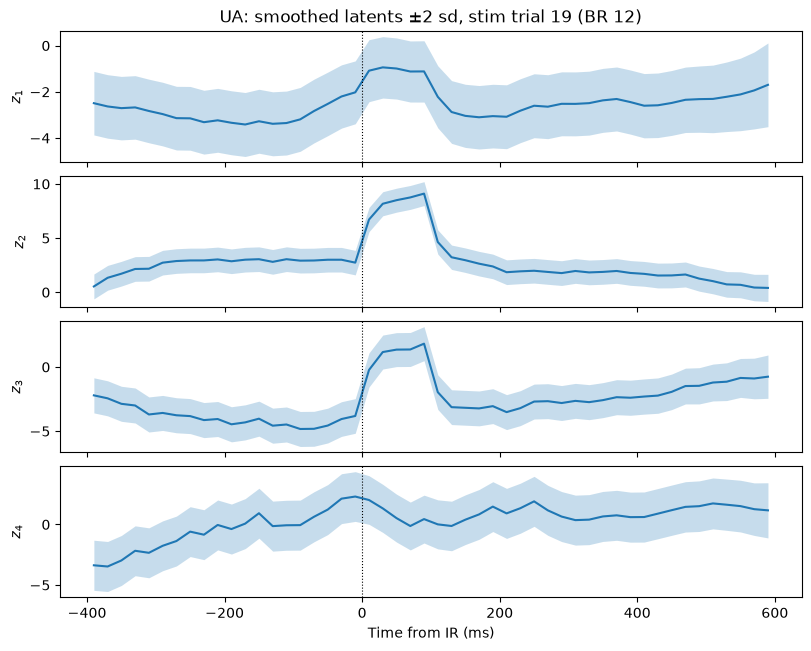

In [31]:
# One example stim trial with its smoothed uncertainty. Inside the blanked window (blanked arrays)
# there are no observations, so the band widens there: the latent is carried by the dynamics and B alone.
trial = int(np.flatnonzero(is_stim)[pattern_id == show_ids[0]][0])

for ARRAY, r in runs.items():
    fig, axes = plt.subplots(STATE_DIM, 1, figsize=(8, 1.6 * STATE_DIM), constrained_layout=True, sharex=True)
    for k, ax in enumerate(axes):
        m, sd = r.z[trial, tp, k], r.z_sd[trial, tp, k]
        ax.fill_between(t_ms[tp], m - 2 * sd, m + 2 * sd, color="tab:blue", alpha=0.25, lw=0)
        ax.plot(t_ms[tp], m, color="tab:blue", lw=1.5)
        shade_blank(ax, r)
        ax.axvline(0, color="k", ls=":", lw=0.8)
        ax.set_ylabel(f"$z_{k + 1}$")
    axes[0].set_title(f"{ARRAY}: smoothed latents ±2 sd, stim trial {trial} (BR {SHOW_BLOCKS[0]})")
    axes[-1].set_xlabel("Time from IR (ms)")
    plt.show()

## Align stim to control on the prestim period

Each stim pattern was recorded in its own block, so the latent state can already differ from
control before anything is delivered (the offsets at −800 ms above). For each pattern, fit
T(z) = z R + t on the prestim bins only, taking that pattern's mean trajectory onto the control
mean, then apply it to every trial of the pattern. Control is left as is. Nothing after stim
onset is used in the fit, so post-stim divergence is measured from a shared starting point. The
window ends where the array stops being observed: at the blanking for blanked arrays (NPRW), at
stim onset otherwise (UA).

In [32]:
ALIGN_MODE = "shift"  # "shift": translation only; "rigid": rotation + translation
ALIGN_FROM_MS = -300.0  # starts late to skip the smoother's warm-up from mu0

# Per array: the prestim fit window ends where the array stops being observed (the blanking, or
# stim onset when the stim window is kept), and "post" starts where it is observed again
for ARRAY, r in runs.items():
    r.align_pre_ms = (ALIGN_FROM_MS, blank_ms[0] if r.blanked else 0.0)
    r.pre_mask = (t_ms >= r.align_pre_ms[0]) & (t_ms < r.align_pre_ms[1])
    r.post_mask = t_ms > blank_ms[1] if r.blanked else t_ms >= 0
    print(f"{ARRAY}: prestim fit window {t_ms[r.pre_mask][0]:.0f} to {t_ms[r.pre_mask][-1]:.0f} ms "
          f"({r.pre_mask.sum()} bins), post from {t_ms[r.post_mask][0]:.0f} ms, mode={ALIGN_MODE}")


def fit_alignment(src, dst, mode):
    """(R, t) with src @ R + t ≈ dst, for (n_bins, K) matched trajectories."""
    mu_src, mu_dst = src.mean(axis=0), dst.mean(axis=0)
    if mode == "shift":
        R_align = np.eye(src.shape[1])
    elif mode == "rigid":
        # Orthogonal Procrustes, reflection excluded so it is a proper rotation. One prestim
        # path per pattern pins a 4-D rotation only weakly, so prefer "shift" unless the
        # prestim trajectories move a lot.
        U_a, _, Vt_a = np.linalg.svd((src - mu_src).T @ (dst - mu_dst))
        D_a = np.eye(src.shape[1])
        D_a[-1, -1] = np.sign(np.linalg.det(U_a @ Vt_a))
        R_align = U_a @ D_a @ Vt_a
    else:
        raise ValueError(f"ALIGN_MODE must be 'shift' or 'rigid', got {mode!r}")
    return R_align, mu_dst - mu_src @ R_align


for ARRAY, r in runs.items():
    r.mean_control = r.z_control.mean(axis=0)
    r.z_stim_al = r.z_stim.copy()
    print(f"{ARRAY}:")
    print(f"{'pattern':>14s} {'angle':>6s} {'|t|':>6s} {'pre before':>11s} {'pre after':>10s} "
          f"{'post before':>12s} {'post after':>11s}")
    for j in range(len(patterns)):
        trials_j = pattern_id == j
        mean_j = r.z_stim[trials_j].mean(axis=0)
        R_align, t_align = fit_alignment(mean_j[r.pre_mask], r.mean_control[r.pre_mask], ALIGN_MODE)
        r.z_stim_al[trials_j] = r.z_stim[trials_j] @ R_align + t_align

        # Mean distance between the control and pattern-mean trajectories, before and after
        mean_al = r.z_stim_al[trials_j].mean(axis=0)
        mean_dist = lambda m, mask: np.linalg.norm((m - r.mean_control)[mask], axis=-1).mean()
        angle = np.degrees(np.abs(np.angle(np.linalg.eigvals(R_align)))).max()
        first, last = np.flatnonzero(patterns[j])[[0, -1]]
        print(f"{f'ch {first}-{last}':>14s} {angle:6.1f} {np.linalg.norm(t_align):6.2f} "
              f"{mean_dist(mean_j, r.pre_mask):11.2f} {mean_dist(mean_al, r.pre_mask):10.2f} "
              f"{mean_dist(mean_j, r.post_mask):12.2f} {mean_dist(mean_al, r.post_mask):11.2f}")

NPRW: prestim fit window -290 to -50 ms (13 bins), post from 150 ms, mode=shift
UA: prestim fit window -290 to -10 ms (15 bins), post from 10 ms, mode=shift
NPRW:
       pattern  angle    |t|  pre before  pre after  post before  post after
        ch 0-7    0.0  15.89       15.91       0.81        13.81        4.22
       ch 4-11    0.0  25.33       25.33       0.76        24.20        2.46
       ch 8-15    0.0  18.02       18.02       0.67        16.40        3.50
      ch 12-19    0.0  12.90       12.91       0.64        12.42        2.06
      ch 16-23    0.0  13.51       13.52       0.69        12.10        2.88
      ch 20-27    0.0  12.82       12.83       0.80        11.23        3.04
      ch 24-31    0.0  12.76       12.77       0.47        10.99        2.84
      ch 28-35    0.0  12.29       12.38       1.44         9.86        3.69
      ch 32-39    0.0  14.00       14.02       0.69        13.14        2.89
      ch 36-43    0.0  10.95       10.98       0.79        10.23   

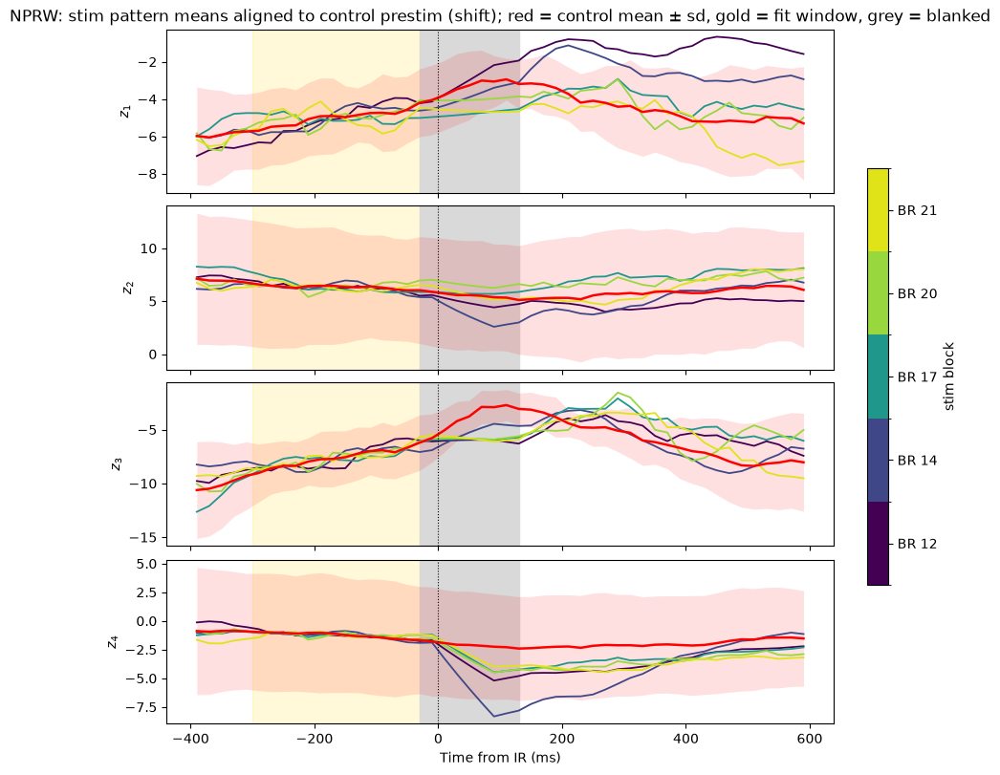

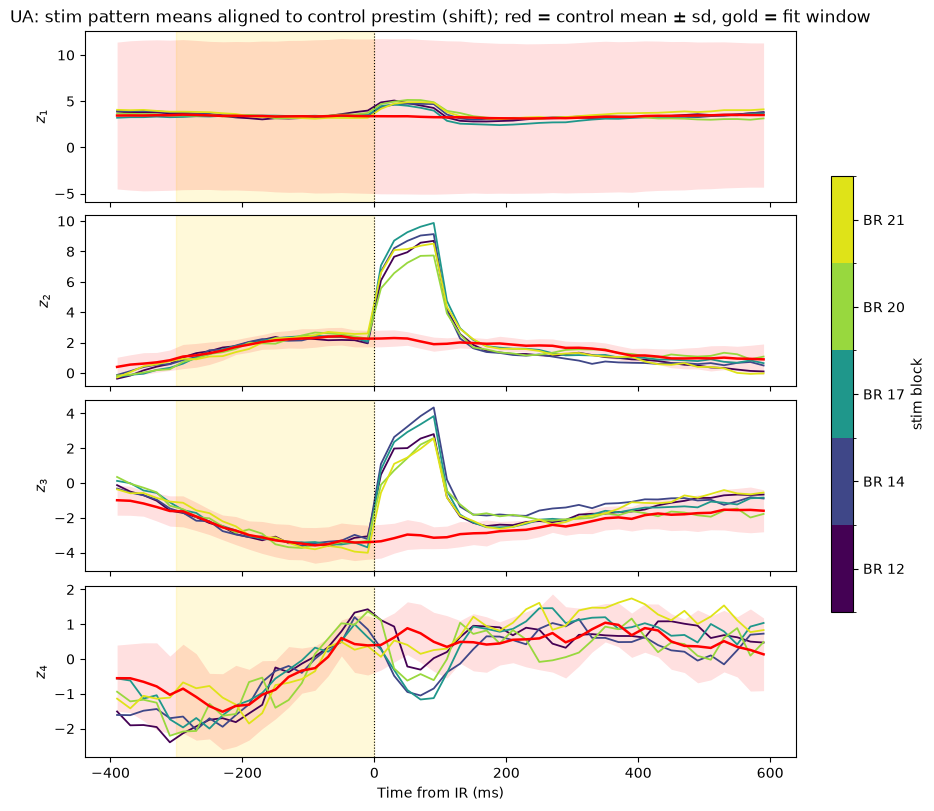

In [33]:
# Same layout as the right column above, with each pattern mapped onto control's prestim.
# Gold band marks the bins the alignment was fit on.
for ARRAY, r in runs.items():
    fig, axes = plt.subplots(STATE_DIM, 1, figsize=(9, 2.0 * STATE_DIM), constrained_layout=True, sharex=True)
    for k, ax in enumerate(axes):
        for j, color in zip(show_ids, colors):
            ax.plot(t_ms[tp], r.z_stim_al[pattern_id == j][:, tp, k].mean(axis=0), color=color, lw=1.3)
        m, sd = r.mean_control[tp, k], r.z_control[:, tp, k].std(axis=0)
        ax.fill_between(t_ms[tp], m - sd, m + sd, color="r", alpha=0.12, lw=0)
        ax.plot(t_ms[tp], m, color="r", lw=1.8)
        ax.axvspan(*r.align_pre_ms, color="gold", alpha=0.15, zorder=0)
        shade_blank(ax, r)
        ax.axvline(0, color="k", ls=":", lw=0.8)
        ax.set_ylabel(f"$z_{k + 1}$")
    axes[0].set_title(f"{ARRAY}: stim pattern means aligned to control prestim ({ALIGN_MODE}); "
                      "red = control mean ± sd, gold = fit window" + (", grey = blanked" if r.blanked else ""))
    axes[-1].set_xlabel("Time from IR (ms)")
    block_colorbar(fig, axes, shrink=0.6)
    plt.show()

## Fan plane: where the stim conditions differ

The z axes are ordered by overall latent variance, so the differences between stim conditions
are spread thinly over all four panels. Here the aligned pattern means are projected onto the
two directions along which they differ most after stimulation: PCA of the pattern means
minus their across-pattern mean, over the post-stim window. Only measured bins set the axes: for
a blanked array (NPRW) the window starts after the blanking, since the trajectory inside it comes
from the model alone (dynamics + B u); for an array kept through stim (UA) it starts at stim onset.
Ellipses are ±2 SEM of each pattern mean, from its trials.

With `FAN_REMOVE_SHARED`, the average stim trajectory (the time course every condition shares)
is subtracted at each time point first, so the plot shows only how the conditions differ from
each other: they start at the origin and fan out. Control is drawn relative to the same average.

With `FAN_EQUAL_AXES`, each fan axis is divided by the between-pattern sd along it, so PC1 and
PC2 get equal visual weight. That stretches the smaller axis: distances are then in sd units per
axis, not latent units, so angles and lengths are not comparable across axes.

NPRW: between-pattern variance in the fan plane: PC1 0.61, PC2 0.26, total 0.87


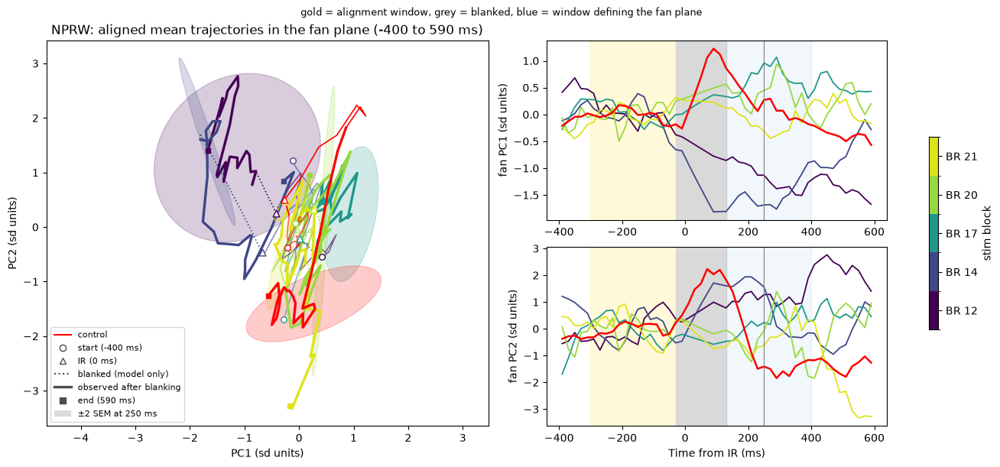

UA: between-pattern variance in the fan plane: PC1 0.42, PC2 0.30, total 0.72


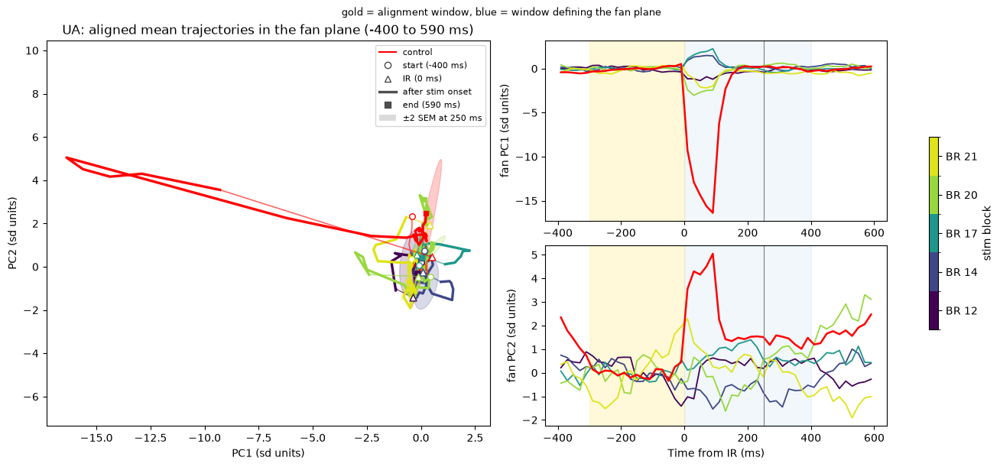

In [34]:
from matplotlib.lines import Line2D
from matplotlib.patches import Ellipse

FAN_TO_MS = 400.0                  # end of the window that defines the fan plane
FAN_EQUAL_AXES = True              # scale each fan axis to unit between-pattern sd
FAN_REMOVE_SHARED = True           # subtract the average stim trajectory at each time
ELLIPSE_MS = 250.0                 # time of the ±2 SEM snapshot

axis_unit = " (sd units)" if FAN_EQUAL_AXES else ""
t_plot = t_ms[tp]
i_zero = int(np.argmin(np.abs(t_plot)))
i_ell = int(np.argmin(np.abs(t_ms - ELLIPSE_MS)))

# Per array: the fan window covers its measured post-stim bins, and paths are drawn thin before
# stim, dotted over the blanked bins (blanked arrays only), and thick once spikes are observed.
# Without blanking i_lo == i_hi, so the dotted piece is empty and the thick piece starts at onset.
for r in runs.values():
    r.fan_win_ms = (blank_ms[1] if r.blanked else 0.0, FAN_TO_MS)
    r.fan_win = (t_ms >= r.fan_win_ms[0]) & (t_ms <= r.fan_win_ms[1])
    if r.blanked:
        r.i_lo, r.i_hi = np.flatnonzero(t_plot <= blank_ms[0])[-1], np.flatnonzero(t_plot >= blank_ms[1])[0]
    else:
        r.i_lo = r.i_hi = int(np.flatnonzero(t_plot >= 0)[0])


def fan_axes(r):
    """Fan plane of one array, stored on `r`: PCA of the between-pattern differences of the
    aligned means in the post-stim window, plus the scaling and origin used by `to_fan`."""
    r.means_al = np.stack([r.z_stim_al[pattern_id == j].mean(axis=0) for j in range(len(patterns))])  # (P, T, K)
    # With a single stim pattern there is nothing to compare across patterns, so use its
    # difference from control instead
    ref = r.means_al[:, r.fan_win].mean(axis=0) if len(patterns) > 1 else r.mean_control[r.fan_win]
    between = r.means_al[:, r.fan_win] - ref
    _, sv, r.Vt = np.linalg.svd(between.reshape(-1, STATE_DIM), full_matrices=False)
    r.U_fan = r.Vt[:2].T  # (K, 2), orthonormal
    frac = sv**2 / (sv**2).sum()
    print(f"{ARRAY}: between-pattern variance in the fan plane: PC1 {frac[0]:.2f}, PC2 {frac[1]:.2f}, "
          f"total {frac[:2].sum():.2f}")

    # Between-pattern sd along each fan axis (the first three, the 3-D view uses PC3)
    r.fan_scale = sv[:3] / np.sqrt(between.shape[0] * between.shape[1]) if FAN_EQUAL_AXES else np.ones(3)
    # Origin at the shared prestim state, so every condition starts near (0, 0)
    # shared: (T, K) time course common to all stim conditions, removed if FAN_REMOVE_SHARED
    r.shared = r.means_al.mean(axis=0) if FAN_REMOVE_SHARED else np.zeros_like(r.mean_control)
    r.origin = (r.mean_control - r.shared)[r.pre_mask].mean(axis=0) @ r.U_fan


def to_fan(r, z, t=slice(None)):
    """Fan-plane coordinates of z (..., T, K), or of z (..., K) at time index t."""
    return ((z - r.shared[t]) @ r.U_fan - r.origin) / r.fan_scale[:2]


def draw_path(r, ax, P, color, lw, blanked=True):
    """Thin before stim, dotted over the blanked bins (if `blanked`), thick once spikes are
    observed again."""
    ax.plot(*P[: r.i_lo + 1].T, color=color, lw=0.8 * lw, alpha=0.6)
    ax.plot(*P[r.i_lo : r.i_hi + 1].T, color=color, lw=0.8 * lw, ls=":" if blanked else "-")
    ax.plot(*P[r.i_hi:].T, color=color, lw=1.6 * lw)
    ax.scatter(*P[0], marker="o", s=30, facecolor="white", edgecolor=color, zorder=5)
    ax.scatter(*P[i_zero], marker="^", s=40, facecolor="white", edgecolor=color, zorder=5)
    ax.scatter(*P[-1], marker="s", s=25, color=color, zorder=5)


def sem_ellipse(ax, pts, color):
    """±2 SEM ellipse of the mean of `pts` (n, 2)."""
    cov = np.cov(pts.T) / len(pts)
    evals, evecs = np.linalg.eigh(cov)
    angle = np.degrees(np.arctan2(evecs[1, -1], evecs[0, -1]))
    ax.add_patch(Ellipse(pts.mean(axis=0), *(4 * np.sqrt(evals[::-1])), angle=angle,
                         facecolor=color, edgecolor=color, alpha=0.2, lw=1))


for ARRAY, r in runs.items():
    fan_axes(r)
    fan_means = to_fan(r, r.means_al)
    fan_control = to_fan(r, r.mean_control)

    fig = plt.figure(figsize=(13, 6), constrained_layout=True)
    grid = fig.add_gridspec(2, 2, width_ratios=[1.3, 1])
    ax = fig.add_subplot(grid[:, 0])
    for j, color in zip(show_ids, colors):
        draw_path(r, ax, fan_means[j, tp], color, lw=1.5, blanked=r.blanked)
        sem_ellipse(ax, to_fan(r, r.z_stim_al[pattern_id == j][:, i_ell], i_ell), color)
    draw_path(r, ax, fan_control[tp], "r", lw=1.5, blanked=False)  # control was never blanked
    sem_ellipse(ax, to_fan(r, r.z_control[:, i_ell], i_ell), "r")
    ax.set_xlabel(f"PC1{axis_unit}"); ax.set_ylabel(f"PC2{axis_unit}"); ax.set_aspect("equal", adjustable="datalim")
    ax.set_title(f"{ARRAY}: aligned mean trajectories in the fan plane ({PLOT_FROM_MS:.0f} to {t_plot[-1]:.0f} ms)")
    ink = "0.3"
    ax.legend(handles=[
        Line2D([], [], color="r", label="control"),
        Line2D([], [], ls="none", marker="o", mfc="white", mec=ink, label=f"start ({PLOT_FROM_MS:.0f} ms)"),
        Line2D([], [], ls="none", marker="^", mfc="white", mec=ink, label="IR (0 ms)"),
        *([Line2D([], [], color=ink, ls=":", label="blanked (model only)")] if r.blanked else []),
        Line2D([], [], color=ink, lw=2.4, label="observed after blanking" if r.blanked else "after stim onset"),
        Line2D([], [], ls="none", marker="s", color=ink, label=f"end ({t_plot[-1]:.0f} ms)"),
        Ellipse((0, 0), 1, 1, facecolor=ink, alpha=0.2, label=f"±2 SEM at {t_ms[i_ell]:.0f} ms"),
    ], fontsize=8, loc="best")

    # The same two coordinates against time: together before stim, apart after
    for row in range(2):
        axt = fig.add_subplot(grid[row, 1])
        for j, color in zip(show_ids, colors):
            axt.plot(t_plot, fan_means[j, tp, row], color=color, lw=1.3)
        axt.plot(t_plot, fan_control[tp, row], color="r", lw=1.8)
        axt.axvspan(*r.align_pre_ms, color="gold", alpha=0.15, zorder=0)
        shade_blank(axt, r)
        axt.axvspan(*r.fan_win_ms, color="tab:blue", alpha=0.06, zorder=0)
        axt.axvline(t_ms[i_ell], color="0.5", lw=0.8)
        axt.set_ylabel(f"fan PC{row + 1}{axis_unit}")
    axt.set_xlabel("Time from IR (ms)")
    block_colorbar(fig, fig.axes, shrink=0.5)
    fig.suptitle("gold = alignment window" + (", grey = blanked" if r.blanked else "")
                 + ", blue = window defining the fan plane", fontsize=9)
    plt.show()

In [35]:
import plotly.colors as pc
import plotly.graph_objects as go
import plotly.io._renderers as _renderers
import nbformat

_renderers.nbformat = nbformat  # plotly's notebook renderer looks this up lazily

# Same fan PC1-3 axes as the next plot, but nothing subtracted and no axis scaling: the shared
# time course is kept, and coordinates are in latent units.
#   "cube": each axis drawn the same length whatever its range, so PC1 is not squashed by the
#           large shared motion on PC2 (a unit is then a different length on each axis)
#   "data": true to scale, a unit is the same length on every axis
RAW_ASPECT = "cube"
hover_raw = "%{text}<br>t = %{customdata:.0f} ms"
idx_marks = [0, i_zero, len(t_plot) - 1]


def to_raw(r, zs):
    """Plotted bins of zs (T, K) on the array's fan PC1-3, in latent units."""
    return zs[tp, :] @ r.U_raw - r.origin_raw


def add_raw(r, zs, name, color, width, blanked=True):
    """Mean trajectory: dotted over the blanking if `blanked`, thick once spikes are observed again."""
    m = to_raw(r, zs.mean(axis=0))
    pieces = [(slice(0, r.i_lo + 1), "solid", 0.6), (slice(r.i_lo, r.i_hi + 1), "dot" if blanked else "solid", 0.6),
              (slice(r.i_hi, None), "solid", 1.4)]
    for n, (sl, dash, scale) in enumerate(pieces):
        r.fig_raw.add_trace(go.Scatter3d(
            x=m[sl, 0], y=m[sl, 1], z=m[sl, 2], mode="lines", name=name, legendgroup=name,
            showlegend=(n == 2), line=dict(color=color, width=4, dash=dash),
            text=[name] * len(t_plot[sl]), customdata=t_plot[sl], hovertemplate=hover_raw,
        ))
    r.fig_raw.add_trace(go.Scatter3d(
        x=m[idx_marks, 0], y=m[idx_marks, 1], z=m[idx_marks, 2], mode="markers",
        marker=dict(size=[4, 5, 4], symbol=["x", "circle-open", "square"], color=color),
        legendgroup=name, showlegend=False,
        text=[f"{name}: start", f"{name}: IR", f"{name}: end"], customdata=t_plot[idx_marks],
        hovertemplate=hover_raw,
    ))


for ARRAY, r in runs.items():
    r.U_raw = r.Vt[:3].T
    r.origin_raw = r.mean_control[r.pre_mask].mean(axis=0) @ r.U_raw
    r.fig_raw = go.Figure()
    add_raw(r, r.z_control, "control", "red", width=6, blanked=False)  # control was never blanked
    for j in show_ids:
        color = pc.sample_colorscale("Viridis", np.linspace(0, 0.95, len(patterns)))[j]
        first, last = np.flatnonzero(patterns[j])[[0, -1]]
        add_raw(r, r.z_stim_al[pattern_id == j], f"stim ch {first}-{last}", color, width=4, blanked=r.blanked)

    r.fig_raw.update_layout(
        title=f"{ARRAY}: mean trajectories <br>"
              + ("<sub>thin = before stim, dotted = blanked (model only), thick = observed after blanking; "
                 if r.blanked else "<sub>thin = before stim, thick = after stim onset; ")
              + f"x = start ({PLOT_FROM_MS:.0f} ms), o = IR, square = end. Click legend to toggle.</sub>",
        scene=dict(xaxis_title="Latent 1", yaxis_title="Latent 2", zaxis_title="Latent 3", aspectmode=RAW_ASPECT),
        legend=dict(itemsizing="constant"),
        margin=dict(l=0, r=0, b=0, t=60), width=1000, height=700,
    )
    # A FigureWidget (needs anywidget) sends the camera back to Python as you rotate, so the next
    # cell can read the view angle
    r.fig_raw = go.FigureWidget(r.fig_raw)
    display(r.fig_raw)

FigureWidget({
    'data': [{'customdata': {'bdata': ('AAAAAABgeMAAAAAAACB3wAAAAAAA4H' ... 'AAAIBRwAAAAAAAAEnAAAAAAAAAPsA='),
                             'dtype': 'f8'},
              'hovertemplate': '%{text}<br>t = %{customdata:.0f} ms',
              'legendgroup': 'control',
              'line': {'color': 'red', 'dash': 'solid', 'width': 4},
              'mode': 'lines',
              'name': 'control',
              'showlegend': False,
              'text': [control, control, control, control, control, control,
                       control, control, control, control, control, control,
                       control, control, control, control, control, control,
                       control],
              'type': 'scatter3d',
              'uid': 'eb117e89-134d-4865-8a70-84f17a987cb8',
              'x': {'bdata': ('0AslvlADcb5QlgW+AMlIvIAuuzzAaC' ... '2wmy0+4P+rPSCLLL6wLxS+AHyYvQ=='),
                    'dtype': 'f4'},
              'y': {'bdata': ('DKc1wMQkMsB8RB3AOJMCwB

FigureWidget({
    'data': [{'customdata': {'bdata': ('AAAAAABgeMAAAAAAACB3wAAAAAAA4H' ... 'AAAAAAPsAAAAAAAAAkwAAAAAAAACRA'),
                             'dtype': 'f8'},
              'hovertemplate': '%{text}<br>t = %{customdata:.0f} ms',
              'legendgroup': 'control',
              'line': {'color': 'red', 'dash': 'solid', 'width': 4},
              'mode': 'lines',
              'name': 'control',
              'showlegend': False,
              'text': [control, control, control, control, control, control,
                       control, control, control, control, control, control,
                       control, control, control, control, control, control,
                       control, control, control],
              'type': 'scatter3d',
              'uid': '4ce04686-91fc-4eee-ac9a-5acc14cdc701',
              'x': {'bdata': ('AP8suxxfsj1QqbA9CDacPU4PDD6gpm' ... 'NFvixPWL7E2ZW+0PnDvgIXvL4qaqu+'),
                    'dtype': 'f4'},
              'y': {'bdata': ('GtcN

showing: ['control', 'stim ch 0-7', 'stim ch 8-15', 'stim ch 20-27', 'stim ch 32-39', 'stim ch 36-43']
NPRW: elev=32.4, azim=15.5
saved ../figures/mean_traj_3d_NPRW_BR12-14-17-20-21_fit12-13-14-15-16-17-18-19-20-21.svg


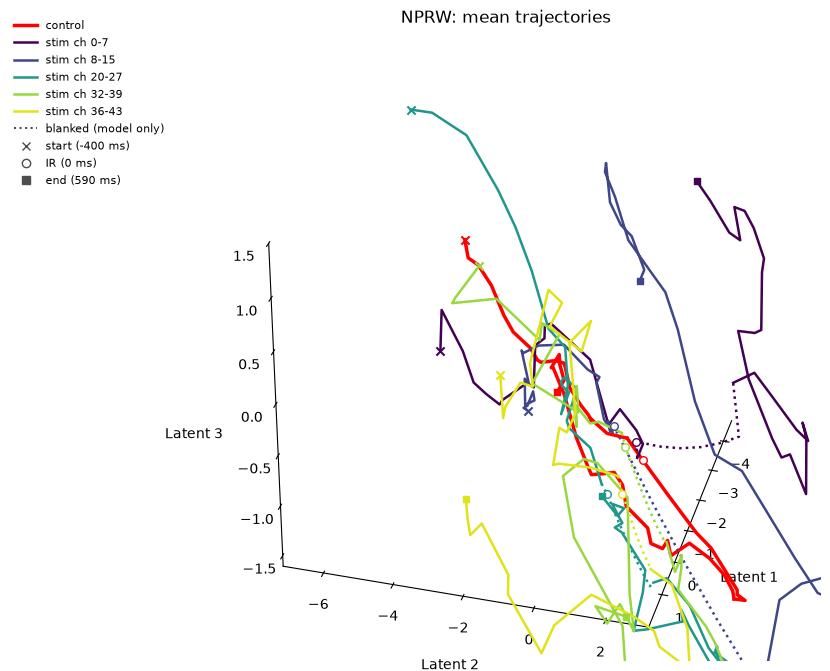

UA: elev=32.4, azim=15.5
saved ../figures/mean_traj_3d_UA_BR12-14-17-20-21_fit12-13-14-15-16-17-18-19-20-21.svg


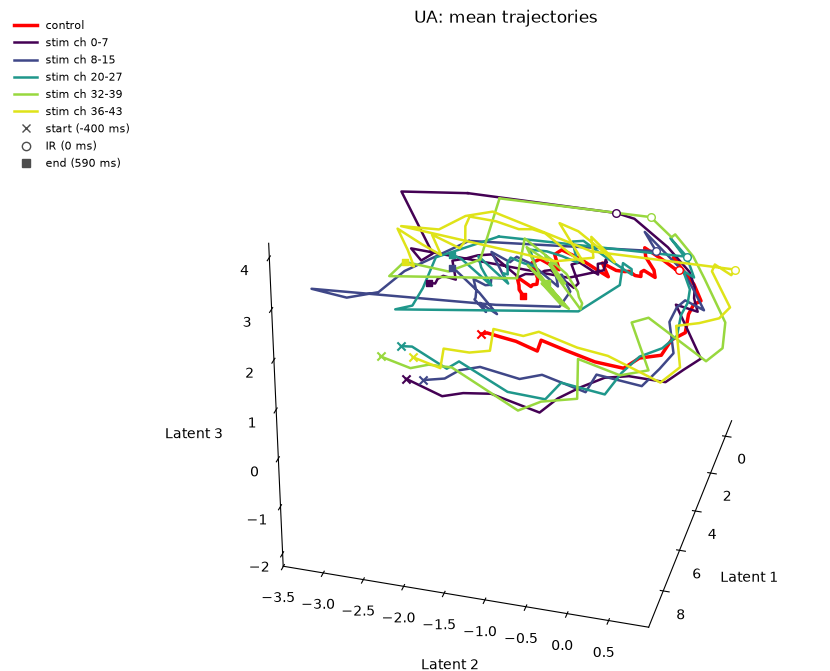

In [36]:
# Matplotlib copy of the plot above, from the same viewpoint. Rotate the plotly figure first,
# then re-run only this cell: it reads the plotly camera and converts it to (elev, azim).
SAVE_PATH = "../figures/mean_traj_3d_{array}_" + FIG_TAG + ".svg"  # one file per array; None to skip saving

# Which conditions to draw:
#   "plotly": the ones currently visible in the plotly figure (click its legend to toggle)
#   a list of names, e.g. ["control", "stim ch 0-7", "stim ch 24-31"]
#   None: all of them
SHOW_CONDITIONS = None

# Shared with the GIFs below, so the stills and the GIFs show the same box from the same angle
TRAJ_VIEW = 32.37, 15.5  # (elev, azim), fixed; "plotly" takes the current plotly camera
# Axis limits per array: "plotly": that array's plotly figure's axis ranges; None: drawn data + 0.1;
# or fixed ((xmin, xmax), (ymin, ymax), (zmin, zmax)), e.g. to keep the 5-block box when showing fewer
TRAJ_LIMS = {
    "NPRW": ((-4.72, 1.98), (-7.17, 3.20), (-1.61, 1.50)),
    "UA": "plotly",
}

def get_plotly_view_and_ranges(fig, scene="scene"):
    """Extracts (elev, azim) and the precise [[xmin, xmax], [ymin, ymax], [zmin, zmax]] limits."""
    # 1. Extract Viewpoint Orientation
    eye = fig.layout[scene].camera.eye
    x, y, z = (1.25, 1.25, 1.25) if eye is None or eye.x is None else (eye.x, eye.y, eye.z)
    elev = float(np.degrees(np.arctan2(z, np.hypot(x, y))))
    azim = float(np.degrees(np.arctan2(y, x)))
    
    # 2. Extract Axis Ranges, as plotly draws them: a range set on the layout wins, otherwise
    # plotly autoranges to the extent of the visible traces. (Zooming a 3D plot moves the camera,
    # not the ranges, so this needs neither Kaleido nor a FigureWidget.)
    shown = [t for t in fig.data if t.visible not in (False, "legendonly")]
    ranges = []
    for a in "xyz":
        r = fig.layout[scene][f"{a}axis"].range
        if r is None:
            v = np.concatenate([np.asarray(t[a], dtype=float).ravel() for t in shown if t[a] is not None])
            r = (np.nanmin(v), np.nanmax(v))
        ranges.append(tuple(r))

    return elev, azim, tuple(ranges)

def traj_view(r):
    """(elev, azim) for array run `r`, from TRAJ_VIEW."""
    return get_plotly_view_and_ranges(r.fig_raw)[:2] if TRAJ_VIEW == "plotly" else TRAJ_VIEW


def traj_limits(r, lims, pts):
    """(lo, hi), each (3,): the plotly ranges if lims is "plotly", fixed ranges, or the extent of
    pts (n, 3) + 0.1 if lims is None."""
    if lims == "plotly":
        return np.array(get_plotly_view_and_ranges(r.fig_raw)[2], dtype=float).T
    if lims is not None:
        return np.array(lims, dtype=float).T
    return pts.min(axis=0) - 0.1, pts.max(axis=0) + 0.1


def plotly_visible(fig):
    """Legend groups not hidden in a FigureWidget (a legend click sets visible="legendonly")."""
    return {t.legendgroup for t in fig.data if t.visible not in (False, "legendonly")}


# Conditions shown under SHOW_CONDITIONS = "plotly" follow the first array's plotly figure
stim_names = [f"stim ch {first}-{last}" for first, last in (np.flatnonzero(patterns[j])[[0, -1]] for j in show_ids)]
if SHOW_CONDITIONS == "plotly":
    shown = plotly_visible(runs[ARRAYS[0]].fig_raw)
elif SHOW_CONDITIONS is None:
    shown = {"control", *stim_names}
else:
    shown = set(SHOW_CONDITIONS)
    unknown = shown - {"control", *stim_names}
    assert not unknown, f"unknown conditions {sorted(unknown)}; choose from {['control', *stim_names]}"
print("showing:", [n for n in ["control", *stim_names] if n in shown])
# Same colours as the GIFs: a single stim condition is blue, several keep their pattern colours
stim_colors = ["b"] if len(show_ids) == 1 else colors


def draw_mean(r, zs, color, label, lw, blanked=True):
    """Same encoding as the plotly figure: dotted over the blanking, x / o / square markers."""
    m = to_raw(r, zs.mean(axis=0))
    drawn.append(m)  # the loop below resets `drawn` and `ax` per array
    ax.plot(*m[: r.i_lo + 1].T, color=color, lw=lw)
    ax.plot(*m[r.i_lo : r.i_hi + 1].T, color=color, lw=lw, ls=":" if blanked else "-")
    ax.plot(*m[r.i_hi:].T, color=color, lw=lw, label=label)
    ax.scatter(*m[0], marker="x", s=35, color=color, depthshade=False, zorder=5)
    ax.scatter(*m[i_zero], marker="o", s=30, facecolor="white", edgecolor=color, depthshade=False, zorder=5)
    ax.scatter(*m[-1], marker="s", s=22, color=color, depthshade=False, zorder=5)


for ARRAY, r in runs.items():
    elev, azim = traj_view(r)
    print(f"{ARRAY}: elev={elev:.1f}, azim={azim:.1f}")

    fig = plt.figure(figsize=(8.5, 7))
    ax = fig.add_axes([0.2, 0.02, 0.8, 0.9], projection="3d")  # left margin holds the legend
    drawn = []

    if "control" in shown:
        draw_mean(r, r.z_control, "red", "control", lw=2.5, blanked=False)  # control was never blanked
    for j, color, name in zip(show_ids, stim_colors, stim_names):
        if name in shown:
            draw_mean(r, r.z_stim_al[pattern_id == j], color, name, lw=1.8, blanked=r.blanked)
    assert drawn, "no conditions selected"

    # TRAJ_LIMS box, then a cube or a true-to-scale box as in plotly
    lo, hi = traj_limits(r, TRAJ_LIMS[ARRAY], np.concatenate(drawn))
    ax.set_xlim(lo[0], hi[0]); ax.set_ylim(lo[1], hi[1]); ax.set_zlim(lo[2], hi[2])
    ax.set_box_aspect((1, 1, 1) if RAW_ASPECT == "cube" else tuple(hi - lo))

    ax.set_proj_type("persp")  
    ax.view_init(elev=elev, azim=azim)

    # Horizontal axis labels, padded clear of the tick labels (as in the GIFs)
    for axis, label, pad in zip((ax.xaxis, ax.yaxis, ax.zaxis), ("Latent 1", "Latent 2", "Latent 3"), (18, 10, 18)):
        axis.set_rotate_label(False)
        axis.set_label_text(label, rotation=0)
        axis.labelpad = pad
    for pane in (ax.xaxis, ax.yaxis, ax.zaxis):
        pane.set_pane_color((1, 1, 1, 0))
    ax.grid(False)
    ink = "0.3"
    handles, _ = ax.get_legend_handles_labels()
    handles += [
        *([Line2D([], [], color=ink, ls=":", label="blanked (model only)")] if r.blanked else []),
        Line2D([], [], ls="none", marker="x", color=ink, label=f"start ({PLOT_FROM_MS:.0f} ms)"),
        Line2D([], [], ls="none", marker="o", mfc="white", mec=ink, label="IR (0 ms)"),
        Line2D([], [], ls="none", marker="s", color=ink, label=f"end ({t_plot[-1]:.0f} ms)"),
    ]
    fig.legend(handles=handles, fontsize=8, loc="upper left", bbox_to_anchor=(0.01, 0.95), frameon=False)
    ax.set_title(f"{ARRAY}: mean trajectories")
    if SAVE_PATH is not None:
        fig.savefig(SAVE_PATH.format(array=ARRAY), bbox_inches="tight")
        print(f"saved {SAVE_PATH.format(array=ARRAY)}")
    plt.show()

## Control vs selected stim conditions

Compares control against this comparison's stim blocks (by BR number), using the aligned
trajectories from above. Left: the smoothed latents z₁..z₄ over time, mean ± SEM across trials.
Bottom left: distance of each condition mean from the control mean in the full latent space.
Right: the mean trajectories in 3-D, on the top three PCs of the drawn means (control and the
selected conditions only), centred on control's prestim state.


In [37]:
def block_name(b):
    first, last = np.flatnonzero(patterns[pattern_block.index(b)])[[0, -1]]
    return f"stim ch {first}-{last}"


def mean_sem(zs):
    return zs.mean(axis=0), zs.std(axis=0, ddof=1) / np.sqrt(len(zs))


def comparison_groups(r, blocks, colors=None):
    """[(name, trials (n, T, K), color, blanked)] for control and each BR block, from array run `r`."""
    groups = [("control", r.z_control, "r", False)]
    cond_colors = [pattern_colors[pattern_block.index(b)] for b in blocks] if colors is None else colors
    for b, color in zip(blocks, cond_colors):
        groups.append((block_name(b), r.z_stim_al[pattern_id == pattern_block.index(b)], color, r.blanked))
    return groups


def project_means(r, means):
    """Plotted-window means (G, T_plot, K) on the top 3 PCs of those means, centred on control's
    prestim state: ((G, T_plot, 3), fraction of variance per PC)."""
    flat = means.reshape(-1, STATE_DIM)
    _, sv_c, Vt_c = np.linalg.svd(flat - flat.mean(axis=0), full_matrices=False)
    U_c = Vt_c[:3].T
    return means @ U_c - r.mean_control[r.pre_mask].mean(axis=0) @ U_c, sv_c**2 / (sv_c**2).sum()


def plot_comparison(r, blocks):
    groups = comparison_groups(r, blocks)

    fig = plt.figure(figsize=(14, 2.0 * (STATE_DIM + 1)), constrained_layout=True)
    grid = fig.add_gridspec(STATE_DIM + 1, 2, width_ratios=[1, 1.1])

    # Left: latents over time, mean ± SEM
    time_axes = [fig.add_subplot(grid[k, 0]) for k in range(STATE_DIM + 1)]
    for k, ax in enumerate(time_axes[:-1]):
        for name, zs, color, _ in groups:
            m, sem = mean_sem(zs[:, tp, k])
            ax.fill_between(t_plot, m - sem, m + sem, color=color, alpha=0.2, lw=0)
            ax.plot(t_plot, m, color=color, lw=1.8 if name == "control" else 1.3, label=f"{name}, n={len(zs)}")
        ax.set_ylabel(f"$z_{k + 1}$")
    time_axes[0].legend(fontsize=7, ncol=2, loc="best")

    # Distance of each condition mean from the control mean
    ax = time_axes[-1]
    for name, zs, color, _ in groups[1:]:
        ax.plot(t_plot, np.linalg.norm(zs.mean(axis=0) - r.mean_control, axis=-1)[tp], color=color, lw=1.3)
    ax.set_ylabel("|mean − control|")
    ax.set_xlabel("Time from IR (ms)")
    for ax in time_axes:
        ax.axvspan(*r.align_pre_ms, color="gold", alpha=0.15, zorder=0)
        shade_blank(ax, r)
        ax.axvline(0, color="k", ls=":", lw=0.8)
        ax.sharex(time_axes[0])

    # Right: 3-D mean trajectories on the PCs of the drawn means
    proj, frac_c = project_means(r, np.stack([zs.mean(axis=0)[tp] for _, zs, _, _ in groups]))
    ax3 = fig.add_subplot(grid[:, 1], projection="3d")
    for (name, _, color, blanked), m in zip(groups, proj):
        lw = 2.5 if name == "control" else 1.8
        ax3.plot(*m[: r.i_lo + 1].T, color=color, lw=0.6 * lw)
        ax3.plot(*m[r.i_lo : r.i_hi + 1].T, color=color, lw=0.6 * lw, ls=":" if blanked else "-")
        ax3.plot(*m[r.i_hi:].T, color=color, lw=lw, label=name)
        ax3.scatter(*m[0], marker="x", s=35, color=color, depthshade=False, zorder=5)
        ax3.scatter(*m[i_zero], marker="o", s=30, facecolor="white", edgecolor=color, depthshade=False, zorder=5)
        ax3.scatter(*m[-1], marker="s", s=22, color=color, depthshade=False, zorder=5)
    ax3.set_xlabel(f"PC1 ({frac_c[0]:.0%})"); ax3.set_ylabel(f"PC2 ({frac_c[1]:.0%})"); ax3.set_zlabel(f"PC3 ({frac_c[2]:.0%})")
    for pane in (ax3.xaxis, ax3.yaxis, ax3.zaxis):
        pane.set_pane_color((1, 1, 1, 0))
    ink = "0.3"
    handles, _ = ax3.get_legend_handles_labels()
    handles += [
        *([Line2D([], [], color=ink, ls=":", label="blanked (model only)")] if r.blanked else []),
        Line2D([], [], ls="none", marker="x", color=ink, label=f"start ({PLOT_FROM_MS:.0f} ms)"),
        Line2D([], [], ls="none", marker="o", mfc="white", mec=ink, label="IR (0 ms)"),
        Line2D([], [], ls="none", marker="s", color=ink, label=f"end ({t_plot[-1]:.0f} ms)"),
    ]
    ax3.legend(handles=handles, fontsize=8, loc="upper left")

    fig.suptitle(f"{ARRAY}: control vs {', '.join(f'BR {b}' for b in blocks)} (aligned on prestim, {ALIGN_MODE}); "
                 "gold = alignment window" + (", grey = blanked" if r.blanked else ""), fontsize=10)
    plt.show()
    return fig

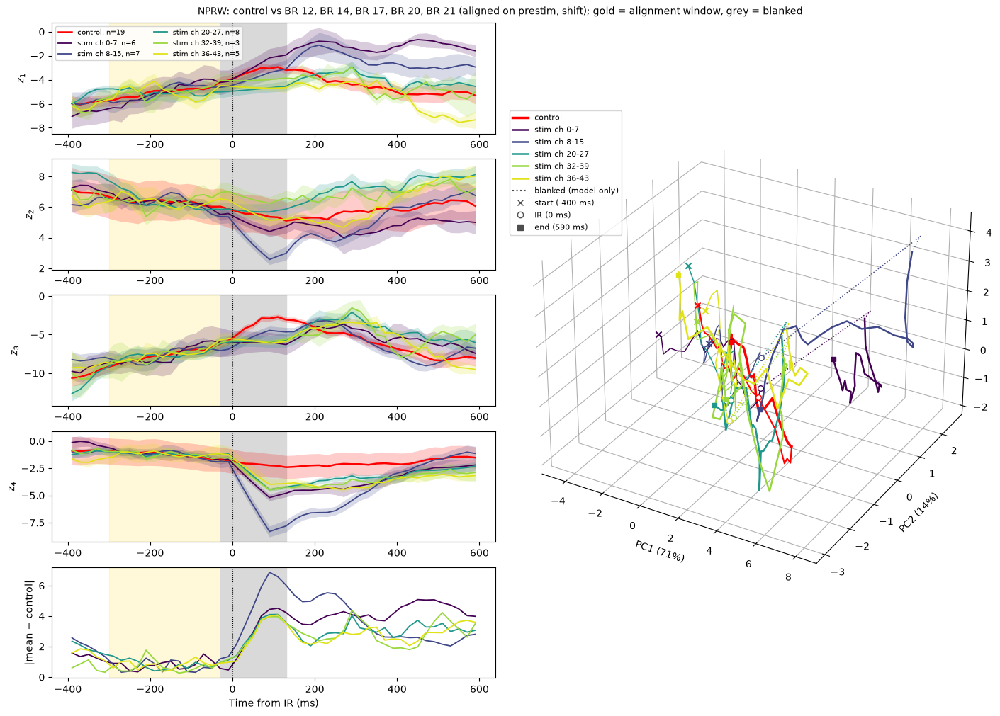

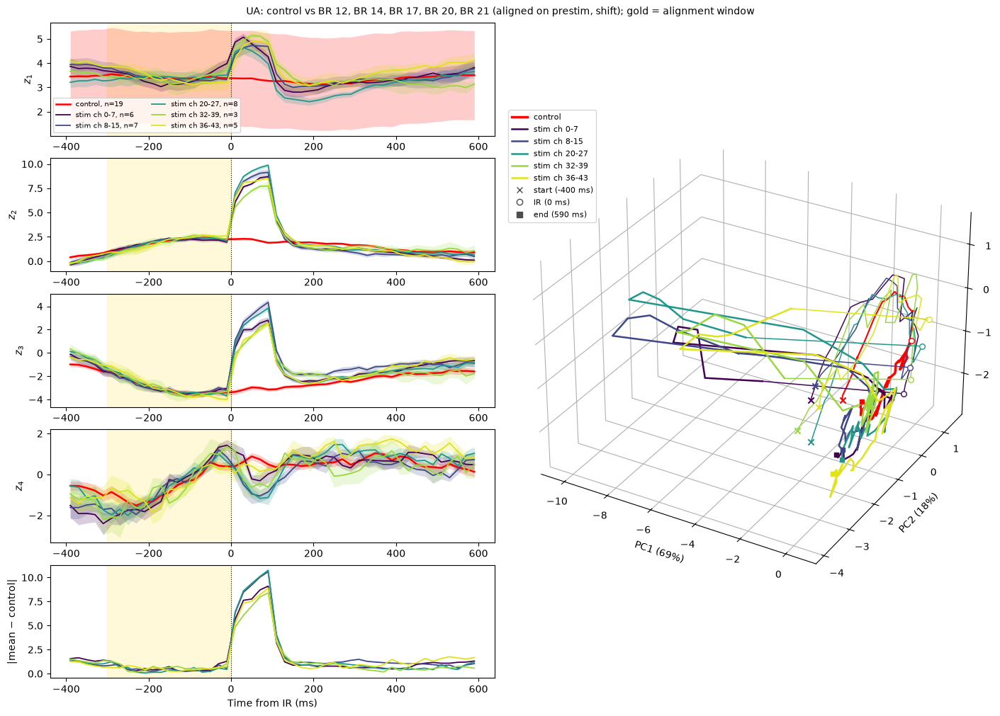

In [38]:
for ARRAY, r in runs.items():
    plot_comparison(r, SHOW_BLOCKS);

### Animated trajectories (GIF)

Mean trajectories drawn faintly in full, with a moving head and a short tail for each condition.
For a blanked array (NPRW), stim trajectories skip the blanked bins: they jump in a straight line
from the last bin before the blanking to the first bin after it. For an array kept through stim (UA)
they move continuously. The tail turns green from IR to `GIF_GREEN_BINS` observed bins later, so
for blanked stim it covers the jump across the blanking. Hollow circles mark IR (orange = control;
blanked stim at the last bin before the blanking). The bolt (`figures/zap.png`) shows while stim is
on. Axes are fan PC1-3, as in the plotly "Mean trajectories" figure (`GIF_AXES = "fan"`); `"z"`
gives z₁..z₃ and `"pc"` the PCs of the 3-D comparison panel. Set `TRAJ_VIEW = "plotly"` to use
the plotly camera as rotated.


In [39]:
from matplotlib.animation import FuncAnimation, PillowWriter

GIF_DIR = Path("../figures")
# "fan": fan PC1-3, the axes of the plotly "Mean trajectories" figure (and its matplotlib copy);
# "z": z1..z3 (principal axes of all latents); "pc": PCs of the drawn means
GIF_AXES = "fan"
GIF_FRAME_MS = 100      # display time per frame
GIF_TAIL = 5           # bins in each moving tail, head included
GIF_GREEN_BINS = 1     # observed bins after IR drawn green (stim: just the jump across the blanking)
# View and axis limits: TRAJ_VIEW and TRAJ_LIMS, set with the still images above
GIF_DPI = 300
ZAP = plt.imread(GIF_DIR / "zap.png")  # shown while stim is on
ZAP_YELLOW = "#ffcb27"  # the bolt's colour, used for the post-stim label


def export_traj_gif(r, blocks, path, lims=None):
    # One stim condition: blue vs red. Several: each condition in its own colour.
    single = len(blocks) == 1
    has_stim = len(blocks) > 0  # control only: no zap, no green after IR, no pre/post-stim label
    groups = comparison_groups(r, blocks, colors=["b"] if single else None)
    means = np.stack([zs.mean(axis=0)[tp] for _, zs, _, _ in groups])  # (G, T, K)
    # Stim: replace the blanked (model-only) bins with a straight line across the blanking, so
    # heads keep moving in step with control. IR is the last bin before the blanking, as on the
    # stim time axis without the blanked bins.
    w = np.linspace(0, 1, r.i_hi - r.i_lo + 1)[:, None]
    ir_idx, green_end = [], []
    for g, (_, _, _, blanked) in enumerate(groups):
        if blanked:
            means[g, r.i_lo : r.i_hi + 1] = (1 - w) * means[g, r.i_lo] + w * means[g, r.i_hi]
        ir_idx.append(r.i_lo if blanked else i_zero)
        green_end.append((r.i_hi if blanked else i_zero) + GIF_GREEN_BINS - blanked if has_stim else i_zero)
    if GIF_AXES == "fan":
        means = means @ r.U_raw - r.origin_raw
        labels = ("Latent 1", "Latent 2", "Latent 3")
    elif GIF_AXES == "z":
        means = means[..., :3]
        labels = ("z₁", "z₂", "z₃")
    elif GIF_AXES == "pc":
        means, _ = project_means(r, means)
        labels = ("Latent 1", "Latent 2", "Latent 3")
    else:
        raise ValueError(f"GIF_AXES must be 'fan', 'z' or 'pc', got {GIF_AXES!r}")
    # IR circle: orange for control, green for stim (or the condition colour when there are several)
    ir_colors = ["orange" if name == "control" else "limegreen" if single else color
                 for name, _, color, _ in groups]

    fig = plt.figure(figsize=(8, 6))
    ax = fig.add_subplot(111, projection="3d")
    for (name, _, color, _), m, ir_color, ir in zip(groups, means, ir_colors, ir_idx):
        ax.plot(*m.T, color=color, lw=1, alpha=0.15, label=name)
        ax.scatter(*m[ir], s=80, facecolors="none", edgecolors=ir_color, lw=1.5, depthshade=False, zorder=5)
    assert lims is None or GIF_AXES == "fan", "TRAJ_LIMS are in fan PC units; use GIF_AXES = 'fan' or lims None"
    lo, hi = traj_limits(r, lims, means.reshape(-1, 3))
    ax.set_xlim(lo[0], hi[0]); ax.set_ylim(lo[1], hi[1]); ax.set_zlim(lo[2], hi[2])
    # Horizontal axis labels (3-D axes otherwise turn them along each axis), padded clear of the
    # tick labels, which a flat label otherwise overlaps on the side axes
    for axis, label, pad in zip((ax.xaxis, ax.yaxis, ax.zaxis), labels, (18, 10, 18)):
        axis.set_rotate_label(False)
        axis.set_label_text(label, rotation=0)
        axis.labelpad = pad
    for axis in (ax.xaxis, ax.yaxis, ax.zaxis):
        axis.pane.fill = False
        axis.pane.set_edgecolor("none")
        axis._axinfo["grid"]["color"] = (1, 1, 1, 0)
    if GIF_AXES == "fan":  # same box and projection as the plotly figure, so its angles carry over
        ax.set_box_aspect((1, 1, 1) if RAW_ASPECT == "cube" else tuple(hi - lo))
        ax.set_proj_type("persp")
    ax.view_init(*traj_view(r))
    # Legend: the faint paths, then one grey hollow circle for the IR marks
    handles, _ = ax.get_legend_handles_labels()
    handles.append(Line2D([], [], ls="none", marker="o", ms=9, mfc="none", mec="0.4", mew=1.5, label="IR crossing"))
    ax.legend(handles=handles, loc="upper right", fontsize=10)
    ax.set_title(ARRAY, loc="left", fontsize=14)
    clock = ax.set_title("", loc="right")
    phase = ax.set_title("", loc="center", fontweight="bold", fontsize=20)

    bolt = fig.add_axes([0.30, 0.70, 0.1, 0.1])  # top left
    bolt.imshow(ZAP)
    bolt.axis("off")
    bolt.set_visible(False)

    # Each tail is three pieces: before IR, green just after IR, the rest
    tails = [[ax.plot([], [], [], color=c, lw=2.5)[0] for c in (color, "limegreen", color)]
             for _, _, color, _ in groups]
    heads = [ax.plot([], [], [], "o", color=color, ms=8, mec="white", mew=0.8, zorder=6)[0]
             for _, _, color, _ in groups]

    def draw(n):
        t = t_plot[n]
        if has_stim:
            phase.set_text("Pre-stim" if t < 0 else "Post-stim")
            phase.set_color("black" if t < 0 else ZAP_YELLOW)
            bolt.set_visible(0 <= t < STIM_DUR_MS)
        clock.set_text(f"t = {t:+.0f} ms")
        start = max(0, n - GIF_TAIL + 1)
        for m, tail, head, ir, ge in zip(means, tails, heads, ir_idx, green_end):
            pieces = [(start, min(n, ir)), (max(start, ir), min(n, ge)), (max(start, ge), n)]
            for line, (a, b) in zip(tail, pieces):
                line.set_data_3d(*m[a : b + 1].T)  # empty when the piece is outside the tail
            head.set_data_3d(*m[n : n + 1].T)
        return [phase, clock, bolt, *heads, *(line for tail in tails for line in tail)]

    anim = FuncAnimation(fig, draw, frames=len(t_plot), interval=GIF_FRAME_MS)
    anim.save(path, writer=PillowWriter(fps=1000 / GIF_FRAME_MS), dpi=GIF_DPI)
    plt.close(fig)
    print(f"saved {path}")


gif_paths = {}
for ARRAY, r in runs.items():
    gif_paths[ARRAY] = GIF_DIR / f"latent_traj_{ARRAY}_control_vs_{FIG_TAG}.gif"
    export_traj_gif(r, SHOW_BLOCKS, gif_paths[ARRAY], TRAJ_LIMS[ARRAY])

saved ../figures/latent_traj_NPRW_control_vs_BR12-14-17-20-21_fit12-13-14-15-16-17-18-19-20-21.gif
saved ../figures/latent_traj_UA_control_vs_BR12-14-17-20-21_fit12-13-14-15-16-17-18-19-20-21.gif


### NPRW and UA side by side

Pastes the two GIFs above frame by frame, NPRW on the left and UA on the right,
with the white margins between them trimmed (`SIDE_PAD` sets how much is kept). Re-run after
the GIF cell.

saved ../figures/latent_traj_NPRW_UA_control_vs_BR12-14-17-20-21_fit12-13-14-15-16-17-18-19-20-21.gif


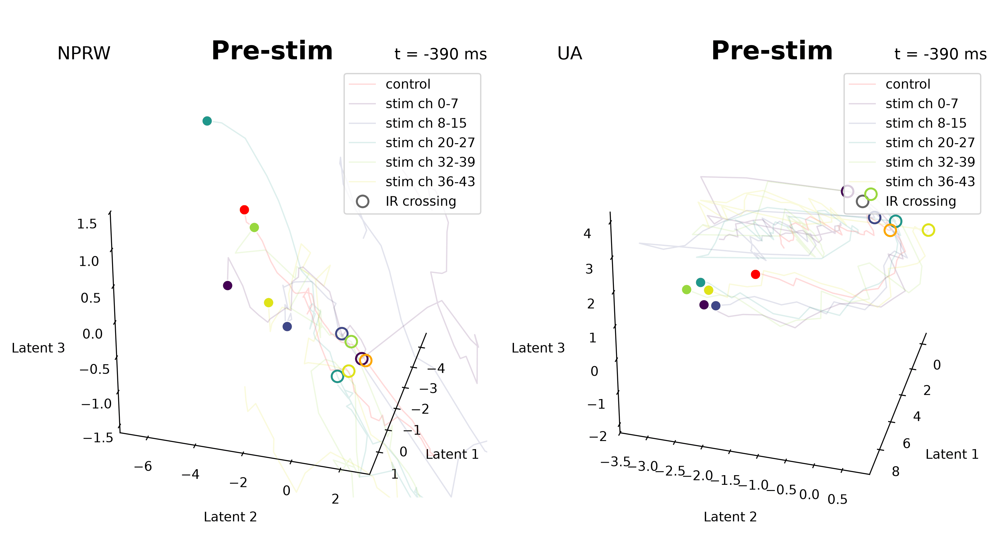

In [ ]:
from IPython.display import Image as IPImage
from PIL import Image, ImageSequence


SIDE_PAD = 40  # px of white kept beside the drawn content of each GIF


def content_cols(frames, pad):
    """(left, right) columns spanning the non-white content of any frame, plus `pad`."""
    ink = np.zeros(frames[0].size[0], bool)
    for f in frames:
        ink |= (np.asarray(f) < 250).any(axis=(0, 2))
    cols = np.flatnonzero(ink)
    return max(cols[0] - pad, 0), min(cols[-1] + 1 + pad, len(ink))


def side_by_side_gif(left, right, path, pad=SIDE_PAD):
    """Paste two GIFs with the same frames next to each other, keeping the left one's timing. The
    white margins left and right of each are trimmed, so the two plots sit close together."""
    with Image.open(left) as a, Image.open(right) as b:
        frames_a = [f.convert("RGB") for f in ImageSequence.Iterator(a)]
        durations = [f.info["duration"] for f in ImageSequence.Iterator(a)]
        frames_b = [f.convert("RGB") for f in ImageSequence.Iterator(b)]
    assert len(frames_a) == len(frames_b), f"{left} has {len(frames_a)} frames, {right} {len(frames_b)}"
    (la, ra), (lb, rb) = content_cols(frames_a, pad), content_cols(frames_b, pad)
    ha, hb = frames_a[0].size[1], frames_b[0].size[1]
    frames = []
    for fa, fb in zip(frames_a, frames_b):
        frame = Image.new("RGB", (ra - la + rb - lb, max(ha, hb)), "white")
        frame.paste(fa.crop((la, 0, ra, ha)), (0, 0))
        frame.paste(fb.crop((lb, 0, rb, hb)), (ra - la, 0))
        frames.append(frame)
    frames[0].save(path, save_all=True, append_images=frames[1:], duration=durations, loop=0)
    print(f"saved {path}")


side_path = GIF_DIR / f"latent_traj_NPRW_UA_control_vs_{FIG_TAG}.gif"
# side_by_side_gif(gif_paths["NPRW"], gif_paths["UA"], side_path)
# display(IPImage(filename=side_path, width=1200))

### Control only

The same GIFs with only the control trajectory, per array and side by side (same axes and view).

saved ../figures/latent_traj_NPRW_control_only.gif
saved ../figures/latent_traj_UA_control_only.gif
saved ../figures/latent_traj_NPRW_UA_control_only.gif


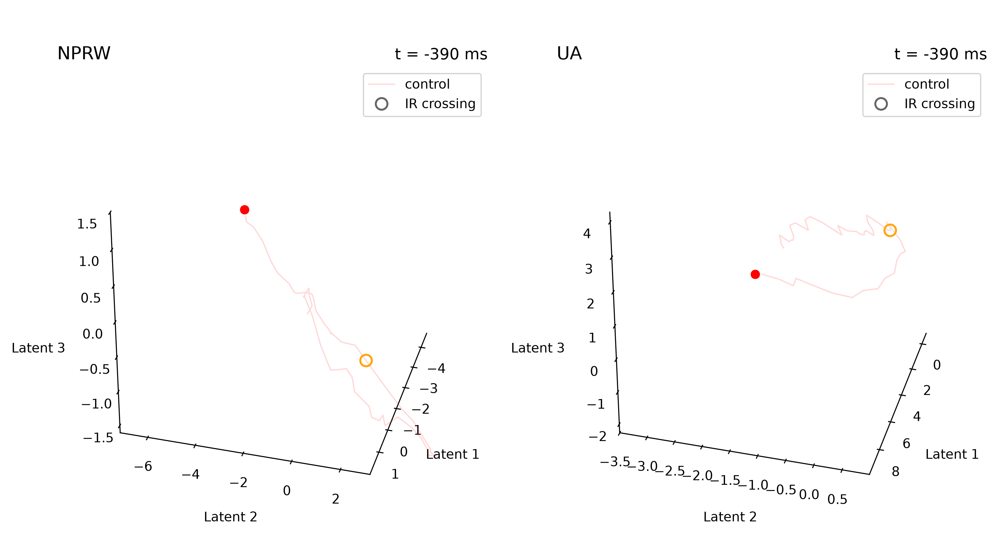

In [ ]:
control_gif_paths = {}
for ARRAY, r in runs.items():
    control_gif_paths[ARRAY] = GIF_DIR / f"latent_traj_{ARRAY}_control_only.gif"
    export_traj_gif(r, [], control_gif_paths[ARRAY], TRAJ_LIMS[ARRAY])

control_side_path = GIF_DIR / "latent_traj_NPRW_UA_control_only.gif"
# side_by_side_gif(control_gif_paths["NPRW"], control_gif_paths["UA"], control_side_path)
# display(IPImage(filename=control_side_path, width=1200))

# UA: blanked vs kept through stim

Refits UA with its stim-window bins dropped (as for NPRW) and compares it with the main UA fit,
which keeps them. The model has no artifact term, so a stim artifact on UA would be absorbed by B.

1. **Stim effect in rate space**, `C B u_j` per pattern: the change in each channel's log-rate
   drive per stim bin. It does not depend on the latent basis, so the two fits compare directly.
2. **Held-out stim window**: the blanked fit never sees UA's stim-window counts, so its smoothed
   rate there is a prediction from the dynamics and B alone. If it already reproduces the observed
   response, the kept bins mostly add neural signal; a response it cannot predict (e.g. a
   uniform jump locked to the stim window) is more artifact-like.

UA blanked: control fit NLL per bin: 116.5053 -> 106.9176
UA blanked: NLL per bin at the end of each EM iteration: [108.1279 108.0662 108.0321 108.0246 108.0195 108.0228 108.027  108.0313
 108.0349 108.0383]
UA blanked: |B| = 1.959, b = 0.074
UA blanked: singular values of A: [0.999  0.999  0.999  0.2808]
UA blanked: fraction of latent variance per axis: [0.732 0.156 0.078 0.034]
per-pattern correlation of C B u (kept vs blanked): [-0.25 -0.19 -0.22 -0.14  0.04 -0.05 -0.03  0.1   0.04 -0.13]
‖C B u‖ per pattern, kept:    [5.85 6.31 6.57 7.07 7.11 6.73 6.03 5.12 5.07 5.59]
‖C B u‖ per pattern, blanked: [0.26 0.32 0.24 0.23 0.37 0.36 0.25 0.58 0.35 0.26]
stim-window change per channel, observed vs kept fit: corr 0.89, mean observed +0.136, kept +0.143 counts/bin
stim-window change per channel, observed vs blanked fit: corr 0.44, mean observed +0.136, blanked +0.011 counts/bin


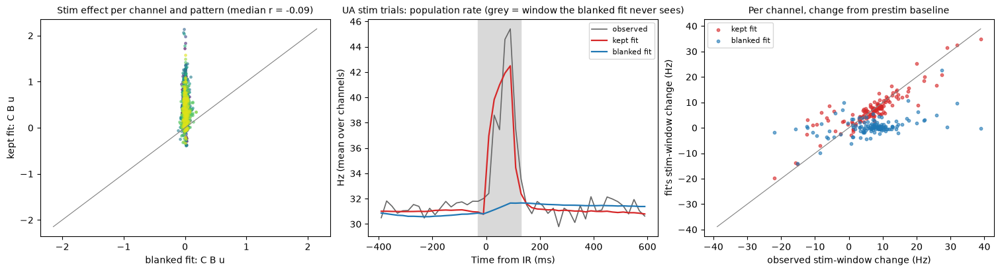

In [42]:
import jax

ua = runs["UA"]
assert not ua.blanked, "the comparison expects the main UA fit to keep its stim window (BLANK['UA'] = False)"

# Same UA counts with the stim-window bins dropped
ua_blanked = SimpleNamespace(
    Y_control=ua.Y_control, Y_stim=ua.Y_stim.at[:, blanked_bins].set(jnp.nan),
    keep_control=ua.keep_control, blanked=True,
)
ua_blanked.keep_stim = jnp.all(jnp.isfinite(ua_blanked.Y_stim), axis=2)
fit_control("UA blanked", ua_blanked)
fit_joint("UA blanked", ua_blanked)
smooth_and_rotate("UA blanked", ua_blanked)
fits = {"kept": ua, "blanked": ua_blanked}


def rate_effects(r):
    """(patterns, N) stim effect C B u_j of each pattern, in log-rate drive per stim bin."""
    U = jax.vmap(r.model.stim_input)(jnp.asarray(patterns))
    return np.asarray(U @ r.B_fit.T @ r.model.observation.C.T)


def smoothed_rates(r):
    """(trials, T, N) smoothed firing rate, counts per bin."""
    return np.asarray(jax.vmap(jax.vmap(r.model.rate))(r.posts.smoothed_means))


effects = {name: rate_effects(r) for name, r in fits.items()}
corr = [np.corrcoef(effects["kept"][j], effects["blanked"][j])[0, 1] for j in range(len(patterns))]
print("per-pattern correlation of C B u (kept vs blanked):", np.round(corr, 2))
print("‖C B u‖ per pattern, kept:   ", np.round(np.linalg.norm(effects["kept"], axis=1), 2))
print("‖C B u‖ per pattern, blanked:", np.round(np.linalg.norm(effects["blanked"], axis=1), 2))

# Held-out stim window: observed vs each fit's smoothed rate, as change from the prestim baseline
Y_stim_obs = np.asarray(ua.Y_stim)                     # kept counts, (stim trials, T, N)
baseline = slice(int(np.flatnonzero(t_ms >= -200)[0]), int(np.flatnonzero(t_ms < blank_ms[0])[-1]) + 1)
observed = Y_stim_obs.mean(axis=0)                     # (T, N)
predicted = {name: smoothed_rates(r)[is_stim].mean(axis=0) for name, r in fits.items()}
window = blanked_bins
change = lambda x: x[window].mean(axis=0) - x[baseline].mean(axis=0)  # (N,) per-channel change
for name in fits:
    print(f"stim-window change per channel, observed vs {name} fit: "
          f"corr {np.corrcoef(change(observed), change(predicted[name]))[0, 1]:.2f}, "
          f"mean observed {change(observed).mean():+.3f}, {name} {change(predicted[name]).mean():+.3f} counts/bin")

hz = 1000.0 / np.median(np.diff(t_ms))
fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
ax = axes[0]
for j, color in enumerate(pattern_colors):
    ax.scatter(effects["blanked"][j], effects["kept"][j], s=6, alpha=0.5, color=color)
lim = np.abs(np.concatenate([effects["kept"].ravel(), effects["blanked"].ravel()])).max()
ax.plot([-lim, lim], [-lim, lim], color="0.5", lw=0.8)
ax.set_xlabel("blanked fit: C B u"); ax.set_ylabel("kept fit: C B u")
ax.set_title(f"Stim effect per channel and pattern (median r = {np.median(corr):.2f})", fontsize=10)

ax = axes[1]
ax.plot(t_ms[tp], observed[tp].mean(axis=1) * hz, color="0.4", lw=1.2, label="observed")
for name, color in (("kept", "tab:red"), ("blanked", "tab:blue")):
    ax.plot(t_ms[tp], predicted[name][tp].mean(axis=1) * hz, color=color, lw=1.6, label=f"{name} fit")
ax.axvspan(*blank_ms, color="0.85", zorder=0)
ax.set_xlabel("Time from IR (ms)"); ax.set_ylabel("Hz (mean over channels)")
ax.set_title("UA stim trials: population rate (grey = window the blanked fit never sees)", fontsize=10)
ax.legend(fontsize=8)

ax = axes[2]
for name, color in (("kept", "tab:red"), ("blanked", "tab:blue")):
    ax.scatter(change(observed) * hz, change(predicted[name]) * hz, s=10, alpha=0.6, color=color, label=f"{name} fit")
lim = np.abs(change(observed) * hz).max()
ax.plot([-lim, lim], [-lim, lim], color="0.5", lw=0.8)
ax.set_xlabel("observed stim-window change (Hz)"); ax.set_ylabel("fit's stim-window change (Hz)")
ax.set_title("Per channel, change from prestim baseline", fontsize=10)
ax.legend(fontsize=8)
plt.show()

# Fit checks

/tmp/ipykernel_1631742/3397285301.py:13: RuntimeWarning: Mean of empty slice
  ax.plot(t_ms[tp], np.nanmean(Y_np[sel][:, tp, ch], axis=0) * hz, color="0.6", lw=1, label="observed")


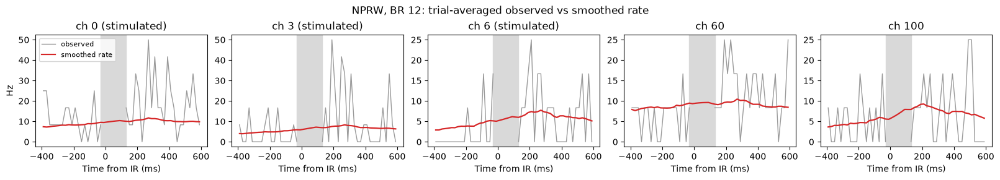

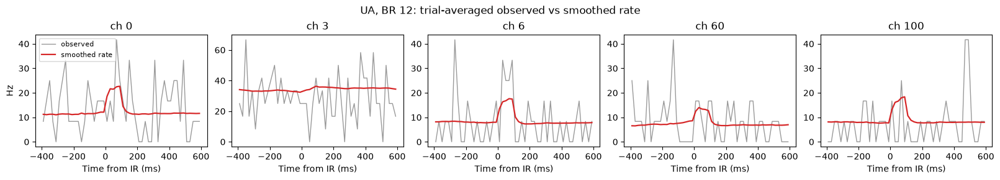

In [43]:
# Smoothed rates against the observed PSTH, for a few channels (NPRW: some stimulated in the
# first displayed block)
hz = 1000.0 / np.median(np.diff(t_ms))
j0 = show_ids[0]
sel = np.flatnonzero(is_stim)[pattern_id == j0]
chans = np.flatnonzero(patterns[j0])[::3][:3].tolist() + [60, 100]

for ARRAY, r in runs.items():
    rate = np.asarray(softplus(r.posts.smoothed_means @ r.model.observation.C.T + r.model.observation.d, BETA_EMIT))
    Y_np = np.asarray(r.Y_all)
    fig, axes = plt.subplots(1, len(chans), figsize=(3.2 * len(chans), 2.8), constrained_layout=True, sharex=True)
    for ax, ch in zip(axes, chans):
        ax.plot(t_ms[tp], np.nanmean(Y_np[sel][:, tp, ch], axis=0) * hz, color="0.6", lw=1, label="observed")
        ax.plot(t_ms[tp], rate[sel][:, tp, ch].mean(axis=0) * hz, color="tab:red", lw=1.6, label="smoothed rate")
        shade_blank(ax, r)
        ax.set_title(f"ch {ch}" + (" (stimulated)" if ARRAY == "NPRW" and patterns[j0, ch] else ""))
        ax.set_xlabel("Time from IR (ms)")
    axes[0].set_ylabel("Hz"); axes[0].legend(fontsize=8)
    fig.suptitle(f"{ARRAY}, BR {SHOW_BLOCKS[0]}: trial-averaged observed vs smoothed rate")
    plt.show()

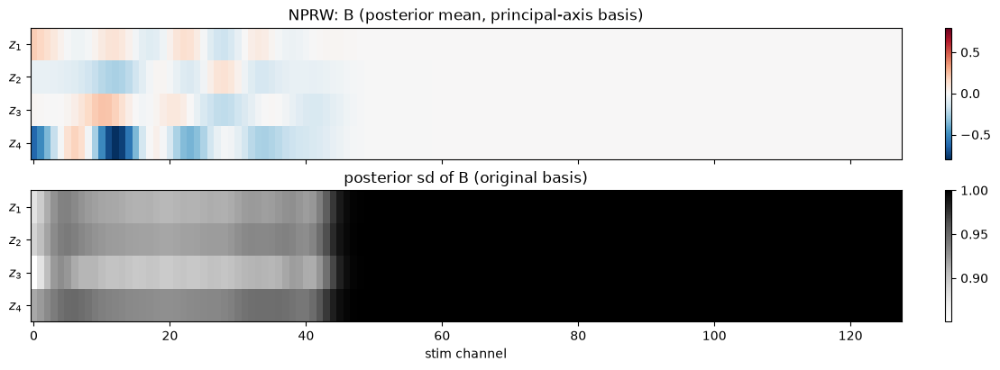

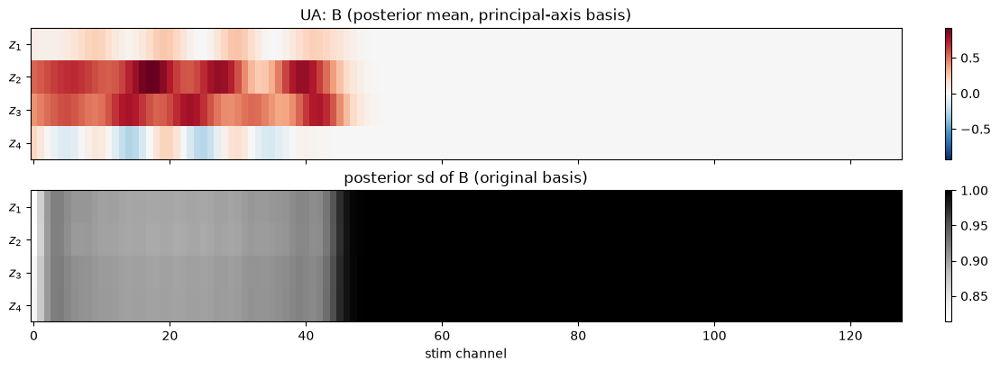

In [44]:
# Fitted B in the principal-axis basis (rows = z, columns = stim channels), and its posterior sd
for ARRAY, r in runs.items():
    B_z = r.R.T @ np.asarray(r.B_fit)
    B_sd = np.sqrt(np.diag(np.asarray(r.B_post.cov))).reshape(n_ch, STATE_DIM).T  # vec stacks columns

    fig, axes = plt.subplots(2, 1, figsize=(11, 4), constrained_layout=True, sharex=True)
    lim = np.abs(B_z).max()
    im = axes[0].imshow(B_z, aspect="auto", cmap="RdBu_r", vmin=-lim, vmax=lim, interpolation="nearest")
    fig.colorbar(im, ax=axes[0]); axes[0].set_title(f"{ARRAY}: B (posterior mean, principal-axis basis)")
    im = axes[1].imshow(B_sd, aspect="auto", cmap="Greys", interpolation="nearest")
    fig.colorbar(im, ax=axes[1]); axes[1].set_title("posterior sd of B (original basis)")
    axes[1].set_xlabel("stim channel")
    for ax in axes:
        ax.set_yticks(range(STATE_DIM), [f"$z_{k+1}$" for k in range(STATE_DIM)])
    plt.show()

## Variance explained: PCA vs batch fit

How much of the trial-by-trial firing rates each array's model captures, against PCA up to all
128 dimensions. The target is the smoothed firing rate saved with the data (`{ARRAY}_rates_hz`,
Gaussian, σ = 20 ms, on the same bins as the counts), in Hz. Both are scored on the same
observed bins (blanked bins left out), as VE = 1 − Σ(r − r̂)² / Σ(r − r̄)², with r̄ each channel's mean:

- **PCA**: r̂ = the rates reconstructed from their top k principal components, fit on the same
  bins, for k = 1 … 128 (VE reaches 1 at full rank). For k dimensions this is the best any
  linear reconstruction can do in squared error.
- **Batch fit**: r̂ = the PLDS's smoothed rate softplus(C x̂ + d), converted to Hz, with x̂ the
  smoothed latents. It is fit to the spike counts by Poisson likelihood, with dynamics and B, not
  to these rates, so it can sit below PCA at the same k and still be the better model of the spikes.

Both are in-sample: they see the bins they are scored on. `VE_STANDARDIZE` z-scores each
channel first, so every channel counts equally instead of the high-rate ones dominating.

In [1]:
VE_STANDARDIZE = False             # True: z-score each channel, so every channel counts equally
VE_THRESHOLDS = (0.5, 0.8, 0.9)    # report how many PCs reach these

PCA_COLOR, FIT_COLOR = "#2a78d6", "#eb6834"
hz = 1000.0 / np.median(np.diff(t_ms))  # bins per second: counts per bin -> Hz


def variance_explained(y, y_hat, axis=None):
    """1 - SSE / SST about each channel's mean; per channel with axis=0."""
    resid = ((y - y_hat) ** 2).sum(axis=axis)
    total = ((y - y.mean(axis=0)) ** 2).sum(axis=axis)
    return 1 - resid / total


def pca_reconstruction(y, k):
    """Rank-k PCA reconstruction of (bins, channels) y, from its own principal axes."""
    mu = y.mean(axis=0)
    U, s, Vt = np.linalg.svd(y - mu, full_matrices=False)
    return mu + (U[:, :k] * s[:k]) @ Vt[:k]


ve = {}
for ARRAY, r in runs.items():
    # Saved smoothed firing rates, same trials and order as Y_all (control files, then stim files)
    rates = np.concatenate(
        [array_counts(f, ARRAY, stim=False, kind="rates_hz") for f in control_files]
        + [array_counts(f, ARRAY, stim=True, kind="rates_hz") for f in stim_files]
    ).transpose(0, 2, 1)                                                     # (trials, T, N), Hz
    assert rates.shape == r.Y_all.shape, f"{ARRAY}: rates {rates.shape}, counts {r.Y_all.shape}"
    fit_rate = hz * np.asarray(softplus(r.posts.smoothed_means @ r.model.observation.C.T
                                        + r.model.observation.d, BETA_EMIT))  # (trials, T, N), Hz
    obs = np.all(np.isfinite(np.asarray(r.Y_all)) & np.isfinite(rates), axis=2)  # observed bins
    trial_is_stim = np.broadcast_to(is_stim[:, None], obs.shape)[obs]
    y, y_fit = rates[obs], fit_rate[obs]                                       # (bins, N)
    keep_ch = y.std(axis=0) > 0                                                # silent channels have no variance
    y, y_fit = y[:, keep_ch], y_fit[:, keep_ch]
    if VE_STANDARDIZE:
        mu, sd = y.mean(axis=0), y.std(axis=0)
        y, y_fit = (y - mu) / sd, (y_fit - mu) / sd

    # In-sample PCA VE for k PCs is the share of variance in the top k components
    s = np.linalg.svd(y - y.mean(axis=0), compute_uv=False)
    ve_pca = np.cumsum(s**2) / np.sum(s**2)                                    # k = 1 .. N
    y_pca_K = pca_reconstruction(y, STATE_DIM)
    ve[ARRAY] = SimpleNamespace(
        ks=np.arange(1, len(ve_pca) + 1), pca=ve_pca, fit=variance_explained(y, y_fit),
        # Per trial type, with the same reconstructions, about that trial type's own channel means
        split={name: (variance_explained(y[m], y_pca_K[m]), variance_explained(y[m], y_fit[m]))
               for name, m in (("control", ~trial_is_stim), ("stim", trial_is_stim))},
        per_ch=(variance_explained(y, y_pca_K, axis=0), variance_explained(y, y_fit, axis=0)),
        n_bins=len(y), n_ch=int(keep_ch.sum()),
    )

    v = ve[ARRAY]
    pcs_for = lambda frac: int(np.searchsorted(v.pca, frac) + 1)   # PCs needed to reach frac
    print(f"{ARRAY}: {v.n_bins} observed bins x {v.n_ch} channels, smoothed rates"
          + (" (z-scored)" if VE_STANDARDIZE else " (Hz)"))
    print(f"  batch fit (K = {STATE_DIM}): VE {v.fit:.3f};  PCA, {STATE_DIM} PCs: {v.pca[STATE_DIM - 1]:.3f};  "
          f"PCA needs {pcs_for(v.fit)} PCs to match the batch fit")
    print("  PCs PCA needs to reach " + ", ".join(f"{t:.0%}: {pcs_for(t)}" for t in VE_THRESHOLDS)
          + f" (of {v.n_ch})")
    for name, (p_ve, f_ve) in v.split.items():
        print(f"  {name:7s} trials: PCA {STATE_DIM} PCs {p_ve:.3f}, batch fit {f_ve:.3f}")

fig, axes = plt.subplots(1, 2 * len(runs), figsize=(6.5 * len(runs), 3.6), constrained_layout=True)
for i, (ARRAY, v) in enumerate(ve.items()):
    ax = axes[2 * i]
    ax.plot(v.ks, v.pca, color=PCA_COLOR, label="PCA")
    ax.plot([STATE_DIM], [v.fit], marker="D", ms=8, color=FIT_COLOR, ls="none", label=f"batch fit (K = {STATE_DIM})")
    ax.axhline(v.fit, color=FIT_COLOR, lw=0.8, ls="--")
    ax.set_xscale("log", base=2)
    ticks = [k for k in (1, 2, 4, 8, 16, 32, 64, 128) if k <= v.ks[-1]]
    ax.set(xlabel="Dimensions", ylabel="Variance explained", title=f"{ARRAY}: VE of firing rate vs dimensions",
           xticks=ticks, xticklabels=[str(k) for k in ticks], ylim=(0, 1.02))
    ax.legend(loc="lower right")

    ax = axes[2 * i + 1]
    p_ch, f_ch = v.per_ch
    ax.scatter(p_ch, f_ch, s=12, color=FIT_COLOR, alpha=0.7, lw=0)
    lo, hi = min(p_ch.min(), f_ch.min(), 0), max(p_ch.max(), f_ch.max())
    ax.plot([lo, hi], [lo, hi], color="0.6", lw=0.8)
    ax.set(xlabel=f"PCA, {STATE_DIM} PCs", ylabel="Batch fit", title=f"{ARRAY}: VE of firing rate per channel")
    ax.set_aspect("equal")
plt.show()

NameError: name 'np' is not defined

## Poisson deviance explained on spike counts

Scores every model against the binned spike counts themselves, with the Poisson likelihood they
are counts under, instead of against a separately smoothed rate. For predicted rates λ (counts
per bin) on the observed bins:

- deviance D(λ) = 2 Σ [y log(y/λ) − (y − λ)], 0 for a model that predicts every count exactly;
- **deviance explained** DE = 1 − D(model) / D(null), with the null predicting each channel's
  mean count, the Poisson counterpart of variance explained;
- **bits per spike** = (log-likelihood of the model − of the null) / (spikes × ln 2).

Models, at k = 1 … 128 dimensions for PCA:

- **Batch fit**: the PLDS's smoothed rate softplus(C x̂ + d), K = `STATE_DIM`.
- **PCA**: the rank-k reconstruction of the counts, clipped below at `PCA_RATE_FLOOR` where it
  goes to zero or negative (the share of clipped predictions is printed). PCA on √counts, squared
  back, is not used: squaring underestimates the rate (the mean of √y is below √ of the mean of
  y), which puts it below the null at low k.

All in-sample: every model sees the bins it is scored on, so PCA keeps improving with k and
reaches the counts exactly at full rank.

In [ ]:
from scipy.special import xlogy

PCA_RATE_FLOOR = 1e-3   # counts per bin (0.05 Hz in 20 ms bins); PCA predictions below it are clipped
PCA_COLOR, FIT_COLOR = "#2a78d6", "#eb6834"


def poisson_deviance(y, lam, axis=None):
    """2 sum[y log(y / lam) - (y - lam)], with 0 log 0 = 0."""
    return 2 * (xlogy(y, y) - xlogy(y, lam) - y + lam).sum(axis=axis)


def deviance_scores(y, lam, axis=None):
    """(deviance explained, bits per spike) of rates `lam` against counts `y`, null = channel means."""
    null = np.broadcast_to(y.mean(axis=0), y.shape)
    d_model, d_null = poisson_deviance(y, lam, axis), poisson_deviance(y, null, axis)
    # log-likelihood gain over the null is half the deviance difference
    return 1 - d_model / d_null, (d_null - d_model) / 2 / (y.sum(axis=axis) * np.log(2))


def pca_rates(y, ks):
    """{k: (rank-k PCA prediction of counts y (bins, N), floored; share of bins floored)}."""
    mu = y.mean(axis=0)
    U, s, Vt = np.linalg.svd(y - mu, full_matrices=False)
    out, recon = {}, np.broadcast_to(mu, y.shape).copy()
    for k in range(1, max(ks) + 1):
        recon += np.outer(U[:, k - 1] * s[k - 1], Vt[k - 1])
        if k in ks:
            out[k] = (np.maximum(recon, PCA_RATE_FLOOR), float((recon < PCA_RATE_FLOOR).mean()))
    return out


dev = {}
for ARRAY, r in runs.items():
    Y = np.asarray(r.Y_all)                                                   # (trials, T, N) counts
    lam_fit = np.asarray(softplus(r.posts.smoothed_means @ r.model.observation.C.T
                                  + r.model.observation.d, BETA_EMIT))         # counts per bin
    obs = np.all(np.isfinite(Y), axis=2)                                      # observed bins
    trial_is_stim = np.broadcast_to(is_stim[:, None], obs.shape)[obs]
    y, lam_fit = Y[obs], lam_fit[obs]
    keep_ch = y.sum(axis=0) > 0                                               # channels with spikes
    y, lam_fit = y[:, keep_ch], lam_fit[:, keep_ch]

    ks = list(range(1, y.shape[1] + 1))
    pca = pca_rates(y, ks)
    curve = np.array([deviance_scores(y, pca[k][0]) for k in ks])           # (k, [DE, bits/spike])
    fit_de, fit_bps = deviance_scores(y, lam_fit)
    lam_pca_K = pca[STATE_DIM][0]
    dev[ARRAY] = SimpleNamespace(
        ks=np.array(ks), curve=curve, fit=(fit_de, fit_bps),
        per_ch=(deviance_scores(y, lam_pca_K, axis=0)[0], deviance_scores(y, lam_fit, axis=0)[0]),
        n_bins=len(y), n_ch=int(keep_ch.sum()),
    )

    d = dev[ARRAY]
    print(f"{ARRAY}: {d.n_bins} observed bins x {d.n_ch} channels, {int(y.sum())} spikes")
    print(f"  batch fit (K = {STATE_DIM}): deviance explained {fit_de:.3f}, {fit_bps:.3f} bits/spike")
    de_K, bps_K = curve[STATE_DIM - 1]
    match = np.flatnonzero(curve[:, 0] >= fit_de)
    print(f"  PCA, {STATE_DIM} PCs:          deviance explained {de_K:.3f}, {bps_K:.3f} bits/spike, "
          f"{pca[STATE_DIM][1]:.1%} of predictions floored")
    print(f"  PCA matches the batch fit at {match[0] + 1 if len(match) else '>' + str(len(ks))} PCs")
    for name, m in (("control", ~trial_is_stim), ("stim", trial_is_stim)):
        de_p, de_f = deviance_scores(y[m], lam_pca_K[m])[0], deviance_scores(y[m], lam_fit[m])[0]
        print(f"  {name:7s} trials: PCA {STATE_DIM} PCs {de_p:.3f}, batch fit {de_f:.3f}")

fig, axes = plt.subplots(1, 2 * len(runs), figsize=(6.5 * len(runs), 3.6), constrained_layout=True)
for i, (ARRAY, d) in enumerate(dev.items()):
    ax = axes[2 * i]
    ax.plot(d.ks, d.curve[:, 0], color=PCA_COLOR, label="PCA")
    ax.plot([STATE_DIM], [d.fit[0]], marker="D", ms=8, color=FIT_COLOR, ls="none", label=f"batch fit (K = {STATE_DIM})")
    ax.axhline(d.fit[0], color=FIT_COLOR, lw=0.8, ls="--")
    ax.set_xscale("log", base=2)
    ticks = [k for k in (1, 2, 4, 8, 16, 32, 64, 128) if k <= d.ks[-1]]
    ax.set(xlabel="Dimensions", ylabel="Deviance explained", title=f"{ARRAY}: deviance explained vs dimensions",
           xticks=ticks, xticklabels=[str(k) for k in ticks])
    ax.legend(loc="upper left")

    ax = axes[2 * i + 1]
    p_ch, f_ch = d.per_ch
    ax.scatter(p_ch, f_ch, s=12, color=FIT_COLOR, alpha=0.7, lw=0)
    lo, hi = min(p_ch.min(), f_ch.min(), 0), max(p_ch.max(), f_ch.max())
    ax.plot([lo, hi], [lo, hi], color="0.6", lw=0.8)
    ax.set(xlabel=f"PCA, {STATE_DIM} PCs", ylabel="Batch fit", title=f"{ARRAY}: per channel")
    ax.set_aspect("equal")
plt.show()